# LMLPG-TQA
## Lagrangian-Multiplier and LP-Guided Trotterized Quantum Annealing for Constrained Combinatorial Optimization

## **Abstract**

I present a hybrid quantum-classical framework for constrained combinatorial optimization based on fixed-schedule Trotterized Quantum Annealing (TQA). The proposed approach combines Lagrangian-inspired penalty encoding, linear programming (LP)-guided problem decomposition, and static interaction pruning to improve the sampling of high-quality feasible solutions while limiting quantum circuit complexity.

Unlike conventional variational approaches that rely on iterative classical optimization of circuit parameters, my method employs a predetermined annealing schedule and penalty coefficients determined during classical preprocessing. The constrained objective is encoded using a linear weight term and a quadratic penalty on deviations from the assigned capacity. LP relaxation guides the allocation of the global capacity between independent problem groups, while static pruning reduces the number of pairwise interactions in the problem Hamiltonian. The resulting Trotterized evolution is implemented without iterative optimization of quantum circuit angles.

The framework is investigated on a 24-item knapsack problem, decomposed into two independent 12-variable subproblems and executed on quantum hardware. It builds on my earlier experiments with ungrouped TQA on knapsack instances of 10 to 15 items, in which I used a sampling budget of 10 × 2^N shots. Because the fixed, coarse Trotterized schedule spreads the probability over many configurations, the best solutions have small individual probabilities: with smaller budgets their position in the frequency ranking was dominated by sampling noise and they could remain far down the list, whereas at 10 × 2^N shots they moved towards the front. In several runs on 15 items the optimal solution was found within the top 1 % of the most frequently sampled configurations. These observations are empirical, drawn from a large number of runs rather than a controlled scaling study. They suggest that the method may offer an effective way of accessing near-optimal solutions without relying on repeated variational parameter optimization, although it requires a higher sampling budget in the experiments considered. For the 24-item problem, a classical reconstruction procedure combines independently sampled group configurations to recover globally feasible solutions, including the exact optimum, even when the complete optimal bitstring is not observed in a single quantum measurement.

These results motivate further investigation of fixed-schedule, penalty-based TQA as a hardware-oriented alternative to variational quantum optimization for constrained problems. In particular, the observed sampling behavior, feasibility-quality trade-off, and resource requirements provide a basis for systematic comparisons with CVaR-based and optimizer-driven approaches.

---

## The name, part by part

| part | meaning | where in this notebook |
|---|---|---|
| **LM** | **Lagrangian Multipliers**: penalty terms based on the Lagrangian approach (`LAM1` linear weight term, `LAM2` quadratic penalty) | theory: [Lagrange multipliers](#doc-lagrange) · tuning: [Step 3](#step-3) · circuit: [Step 4](#step-4) |
| **LP** | **Linear Programming**: the LP relaxation splits the capacity between the groups and sets the search window for `LAM1` | [Step 1](#step-1) · [Step 2](#step-2) |
| **G** | **Guided**: LP-guided decomposition, i.e. how the items are dealt into groups and which capacities each group gets | [Step 1](#step-1) |
| **TQA** | **Trotterized Quantum Annealing**: quantum annealing discretized by the Trotter decomposition, fixed schedule, no optimized angles | theory: [QUBO → Ising → annealing](#doc-theory) · circuit: [Step 4](#step-4) |

Two more ingredients from the abstract that are not in the acronym: **static interaction pruning** ([Step 4](#step-4)) and the **classical reconstruction** of the global solution from the group samples ([Step 8](#step-8), [Step 10](#step-10)).

### LM — Lagrangian multipliers

The constraint $\sum_i w_i x_i \le C$ is moved into the objective as $E(x) = -\alpha V(x) + \lambda_1 W(x) + \lambda_2 (W(x)-C)^2$, written for each group with its own capacity `cap`. In the circuit cell of [Step 4](#step-4):

```python
lin[i] += -ALPHA * vals[i]                        # value
lin[i] +=  LAM1 * wts[i]                          # Lagrangian linear weight term
lin[i] +=  LAM2 * (wts[i]**2 - 2*cap*wts[i])      # quadratic penalty, linear part
raw[(i, j)] = 2 * LAM2 * wts[i] * wts[j]          # quadratic penalty, pairwise part
```

`LAM1`, `LAM2` (and `STEPS`, `T`) are chosen in classical preprocessing by `tune_penalties2` ([Step 2](#step-2)), which scores every candidate by the statevector P(optimum) of the circuit that will run; [Step 3](#step-3) runs it for every group and capacity.

### LP — linear programming relaxation

Filling the knapsack greedily by value/weight gives the LP relaxation. Its break item sets both the capacity split between the groups ([Step 1](#step-1)) and the shadow price around which `LAM1` is searched ([Step 2](#step-2)):

```python
lp_guess[GROUP_OF[i]] += take                     # Step 1: LP share of the capacity per group
l1_range = (auto_window[0] * d * alpha_out, ...)  # Step 2: LAM1 window around the LP dual d
```

### G — guided decomposition

The items are sorted by value/weight and dealt alternately into groups A and B; group A gets the LP share plus a shift, group B the rest, so every capacity variant (one PUB) sums to the full capacity ([Step 1](#step-1)):

```python
GROUP_ITEMS = [sorted(order[0::2]), sorted(order[1::2])]
capA = int(round(lp_guess[0] + d * CAPACITY))     # d in CAP_SHIFTS, capB = CAPACITY - capA
```

### TQA — Trotterized quantum annealing, and static pruning

Each group gets its own fixed-schedule annealing circuit; both groups run side by side in one circuit on separate qubits, with no gate between them, so the depth is that of one group ([Step 4](#step-4)):

```python
quad = {kk: v for kk, v in raw.items() if abs(v) >= cut}   # static pruning (PRUNE_KEEP)
s = (p + 0.5) / STEPS                                      # midpoint schedule, mixer never vanishes
qc.rz(2 * t_prob * h[j], j); qc.rzz(2 * t_prob * Jjl, j, l); qc.rx(-2 * t_mix, j)
joint.compose(qc_g, qubits=it, inplace=True)               # group qubit j -> item it[j]
```

---

## How to read this notebook

| step | what it does |
|---|---|
| [Step 1](#step-1) | settings, the 24-item instance, groups A/B and the LP-guided capacity plan (5 PUBs) |
| [Step 2](#step-2) | the penalty tuning tool `tune_penalties2` and `lp_dual` |
| [Step 3](#step-3) | tuning `LAM1`/`LAM2`/`STEPS`/`T` for every group at every capacity |
| [Step 4](#step-4) | QUBO, pruning, ground-state check, Ising, Trotterized circuits, both groups side by side |
| [Step 5](#step-5) | backend and noise-aware transpilation (layout map, ISA circuit) |
| [Step 6](#step-6) | shots per PUB and the run on IBM Quantum (one job per PUB in a Batch) |
| [Step 7](#step-7) | results per PUB: summary, P(feasible)/P(optimum), bitstrings to compare with the IBM output, plots |
| [Step 8](#step-8) | all PUBs together and the classical reconstruction of the global solution, counts saved to JSON |
| [Step 9](#step-9) | fair test: reconstruction from the K most frequent parts versus uniformly random bitstrings |
| [Step 10](#step-10) | blind reconstruction: finds the best solution without knowing the optimum |
| [Step 11](#step-11) | picture: how two IBM shots compose the optimum, and where they are in the plots |

The cells right after this one describe the N = 24 group version in more detail, the QUBO → Ising → annealing theory, the tuning tool and the role of the Lagrange multipliers.

**Results at a glance** (ibm_kingston, N = 24, capacity 92, 5 PUBs): every group sampled its own optimum in every PUB; the exact optimum 490 was never measured as a single shot, but the blind reconstruction assembled it from the 16 most frequent parts of each group (out of 4,096). The same procedure on uniformly random bitstrings reached at most 452 even with the 100 most frequent parts.

---

## How this notebook evolved

A year ago I started experimenting with annealing-style QAOA using Trotterization, to get around the slow classical optimizers needed for QUBO problems in Ising form. With a fixed annealing schedule and no optimized angles, it is no longer really QAOA but Trotterized quantum annealing (TQA). Lagrange multipliers came next, to get better results than CVaR-based optimization and to extract the optimum even on a QPU at the edge of the noise. In the current version the items are split into groups whose capacities are guided by the LP relaxation, and the pairwise interactions are statically pruned, which keeps the circuit shallow and fast. The results show that the optimal solutions of the individual groups (dense, high-value items at a lower capacity) are themselves parts of the global optimum.

---

## Licence

**PolyForm Noncommercial License 1.0.0**
***10.5281/zenodo.23860344***

# N = 24 in two groups side by side

This version of the notebook solves a knapsack with **24 items** on circuits whose depth corresponds to **12 qubits**. The procedure:

1. **Splitting the items.** The items are sorted by value/weight ratio and dealt alternately into groups **A** and **B** of 12 each. Each group therefore contains both good and poorer items.
2. **Splitting the capacity.** The LP relaxation estimates how much of the capacity goes to A and how much to B. The estimate may be off, so **several variants** are run: A gets the estimate plus a shift (−20 %, −10 %, 0, +10 %, +20 % of C) and B gets the rest up to C. **The capacities always add up to exactly C.**
3. **Both groups side by side in one circuit.** Each group has its own QUBO, its own LAM1/LAM2/STEPS/T tuning and its own anneal. In the circuit they are two independent blocks on separate qubits, with no gate between the groups. The depth is therefore that of 12 qubits, not 24. One capacity variant = one **PUB**. By default (`RUN_MODE = "batch"`) each PUB is sent as a separate job inside one **Batch**, with its own shots, its own monitor and its own `TIME BREAKDOWN`.
   Fractional gates are off by default (`USE_FRACTIONAL_GATES = False`), as in the successful N = 15 run (`cz` only), so that gate twirling works. When they are switched on, gate twirling is turned off automatically, because IBM does not allow it together with `rzz`/`rx` (error 1519).
4. **Qubit q = item q.** Every measured 24-bit string is therefore directly a selection of all 24 items, in the same convention as before: item 0 is on the right. Bitstrings in the printouts, in the plots and in the IBM output (Workloads → job → results of PUB 0…4, register `meas`) can be compared directly.
5. **Combining the groups.** Besides the best single shot, the best combination of *partial* solutions of A and B from all PUBs with total weight ≤ C is composed classically at the end. For the knapsack, the part of the optimum that lies in a group is itself the optimum of that group at its own capacity. So if every group samples its part somewhere, the combination yields the overall optimum.

**Outputs:** for every group and capacity the `tune_penalties2` table and the exact ideal P(opt) of the circuit that actually runs (with pruning; the tuner scores the circuit without it, and the shots in `auto` mode are computed from the exact value); for every PUB the logical circuit, the transpilation, the layout map and the ISA circuit; the job monitor with `TIME BREAKDOWN`; for every PUB the `RESULT SUMMARY`, P(feasible)/P(optimum), a table of the most frequent bitstrings to compare with the IBM output, and both plots. At the end the plots of all PUBs together, the result of combining the groups and all counts saved to JSON.

**`DRY_RUN = True`** transpiles on a fake backend (layout map, gates and ISA circuit as on the hardware) but samples **ideally, without noise**, group by group from the statevector. A noisy simulation of 24 qubits would be far too slow. The dry run therefore checks the whole procedure and the printouts, not the hardware noise.

<a id="doc-theory"></a>

# Knapsack problem as a QUBO → Ising → quantum annealing


## 1. The optimization problem

With item values $v_i$ (`values`), weights $w_i$ (`weights`) and capacity $C$ (`CAPACITY`):

$$
\max_{x\in\{0,1\}^N}\ \sum_{i=0}^{N-1} v_i\,x_i
\qquad\text{subject to}\qquad
\sum_{i=0}^{N-1} w_i\,x_i \;\le\; C .
$$

A quantum annealer minimizes energy, so we flip the sign of the objective and minimize $-\sum_i v_i x_i$.

---

## 2. Inequality → equality with a slack variable

A QUBO can only encode **equalities**, so we turn the "$\le$" into "$=$" by adding a slack $S$:

$$
\sum_i w_i x_i + S = C ,
\qquad S \in \{0,1,\dots,C\}.
$$

Any feasible selection ($\sum_i w_i x_i \le C$) can satisfy this exactly by choosing $S = C-\sum_i w_i x_i$.

$S$ is stored in **binary** with a bounded log-encoding (`slack_coeffs`):

$$
S=\sum_{k=0}^{K-1} a_k\,s_k,\qquad
a_k = 2^{k}\ (k<K-1),\qquad
a_{K-1}=C-\bigl(2^{K-1}-1\bigr),\qquad
K=\lfloor\log_2 C\rfloor + 1 .
$$

The capped last coefficient $a_{K-1}$ makes the maximum representable value exactly $C$ (so we don't waste qubits), while still covering every integer in $[0,C]$. This costs only $K\approx\log_2 C$ extra qubits.

---

## 3. Penalty and the full QUBO

We add a quadratic penalty that is $0$ when the constraint holds and positive otherwise:

$$
H \;=\; -\sum_i v_i x_i \;+\; P\Bigl(\sum_i w_i x_i + S - C\Bigr)^{2},
\qquad P=\max_i v_i + 1 .
$$

$P$ must exceed the objective gain of any single feasibility violation; $\max_i v_i+1$ is a safe, tunable choice.

**Unify the variables.** Let

$$
y=(x_0,\dots,x_{N-1},\,s_0,\dots,s_{K-1}),\qquad n=N+K,\qquad
c_j=\begin{cases} w_j & j<N \quad(\text{item})\\[2pt] a_{j-N} & j\ge N \quad(\text{slack}) \end{cases}
$$

and write the constraint residual $g=\sum_j c_j y_j - C$. Since $y_j\in\{0,1\}\Rightarrow y_j^2=y_j$,

$$
P\,g^2 = P\!\sum_j\bigl(c_j^2-2C c_j\bigr)y_j \;+\; 2P\!\!\sum_{j<l} c_j c_l\, y_j y_l \;+\; P C^2 .
$$

So the QUBO coefficients used in the code are

$$
\underbrace{\text{lin}[j]}_{\text{diagonal}} = -v_j\,[\,j<N\,] + P\bigl(c_j^2 - 2C c_j\bigr),
\qquad
\underbrace{\text{quad}[j,l]}_{\text{off-diagonal}} = 2P\,c_j c_l,
\qquad
\text{offset}=P C^2,
$$

where $[\,j<N\,]$ is $1$ for item variables and $0$ for slack variables.

---

## 4. QUBO → Ising Hamiltonian

Quantum hardware works with spins $Z_j\in\{+1,-1\}$, so substitute

$$
y_j=\frac{1-Z_j}{2}
\qquad\bigl(y_j=0\leftrightarrow Z_j=+1,\quad y_j=1\leftrightarrow Z_j=-1\bigr).
$$

Plugging in and collecting terms gives the Ising form

$$
H=\sum_j h_j\,Z_j+\sum_{j<l} J_{jl}\,Z_jZ_l+\text{const},
$$

with (exactly what the code accumulates into `h` and `J`)

$$
h_j=-\tfrac12\,\text{lin}[j]\;-\;\tfrac14\!\!\sum_{l\,:\,(j,l)\in\text{quad}}\!\!\text{quad}[j,l],
\qquad
J_{jl}=\tfrac14\,\text{quad}[j,l].
$$

The constant only shifts all energies equally, so it is irrelevant for sampling and is dropped.

**Normalization.** We finally divide every $h_j,J_{jl}$ by $\max(|h_j|,|J_{jl}|)$ so the problem energy scale is $\mathcal{O}(1)$, comparable to the mixer below. Without this, the penalty (magnitude $\sim$ thousands) would completely dominate the mixer ($\sim 1$) and the anneal would not be adiabatic. Decoding reads bits directly, so rescaling the Hamiltonian is harmless.

---

## 5. Digitized (Trotterized) quantum annealing — no optimizer

Two Hamiltonians:

$$
H_M=-\sum_j X_j \quad(\text{mixer, ground state }|+\rangle^{\otimes n}),
\qquad
H_P=\sum_j h_j Z_j+\sum_{j<l} J_{jl} Z_jZ_l \quad(\text{problem}).
$$

Start in $|+\rangle^{\otimes n}$ and interpolate linearly from mixer to problem,

$$
H(s)=(1-s)\,H_M+s\,H_P,\qquad s:0\to1,
$$

discretized into `STEPS` Trotter steps with $s_p=p/\text{STEPS}$ and $\Delta t=T/\text{STEPS}$:

$$
U_p=\underbrace{e^{-i\,\Delta t\,s_p\,H_P}}_{\text{problem layer}}\;
     \underbrace{e^{-i\,\Delta t\,(1-s_p)\,H_M}}_{\text{mixer layer}} .
$$

There is **no classical optimizer** — the schedule is fixed, exactly like a D‑Wave anneal. `STEPS` / `T` play the role of `num_sweeps` / anneal time.

---

## 6. Why the $R_{ZZ}$ (and $R_Z$) gates commute — and why that matters

Every term in $H_P$ is **diagonal** (built only from $Z$ and $Z\!\otimes\! Z$). Diagonal operators all commute:

$$
[\,Z_a,\,Z_bZ_c\,]=0,\qquad [\,Z_aZ_b,\,Z_cZ_d\,]=0 .
$$

Therefore the exponential of the *whole* problem layer factorizes **without any Trotter error**:

$$
e^{-i t H_P}=\prod_j e^{-i t\,h_j Z_j}\;\prod_{j<l} e^{-i t\,J_{jl} Z_jZ_l}
\qquad(\text{exact}).
$$

Two useful consequences:

- **Order-independence.** Because the $R_{ZZ}$ factors commute, they can be applied in *any* order (and reordered/parallelized freely by the transpiler) — the resulting unitary is identical.
- **The only approximation is between layers.** The mixer terms $-X_j$ likewise all commute with each other, so $e^{-i t H_M}=\prod_j e^{+itX_j}$ is also exact. The *sole* Trotter error comes from $[\,H_M,H_P\,]\neq 0$, i.e. from splitting each step into a mixer layer and a problem layer. That discretization error is the annealing granularity, controlled by `STEPS` (more steps ⇒ smoother anneal, but a deeper circuit).

### Gate translations (what the code emits)

Using $R_Z(\theta)=e^{-i\theta Z/2}$, $R_{ZZ}(\theta)=e^{-i\theta\,Z\otimes Z/2}$, $R_X(\theta)=e^{-i\theta X/2}$:

$$
e^{-i t\,h_j Z_j}=R_Z(2 t\,h_j),\qquad
e^{-i t\,J_{jl} Z_jZ_l}=R_{ZZ}(2 t\,J_{jl}),\qquad
e^{+i t\,X_j}=R_X(-2 t).
$$

which is exactly

```python
qc.rz (2 * t_prob * h[j],   j)       # problem: single-Z
qc.rzz(2 * t_prob * J[j,l], j, l)    # problem: ZZ coupling (all mutually commuting)
qc.rx (-2 * t_mix,          j)       # mixer:  -X_j
```

with `t_prob = dt * s_p` and `t_mix = dt * (1 - s_p)`.

In [1]:
import os
import platform
import shutil
import subprocess
import sys

import qiskit
from qiskit.circuit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import array_to_latex, plot_histogram, plot_state_qsphere
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import Batch, QiskitRuntimeService
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler

import matplotlib.pyplot as plt

print(f"Qiskit version: {qiskit.__version__}")


Qiskit version: 2.6.1


In [2]:
# IBM Quantum account: paste your token and instance, run this cell once.
# With token = "..." saving is skipped and the account saved earlier is used.
token = "..."
instance = "..."  # looks like "crn:v1:bluemix:public:quantum-computing:..."

if token != "...":
    QiskitRuntimeService.save_account(
        channel="ibm_quantum_platform",
        token=token,
        instance=instance,
        overwrite=True,
        set_as_default=True,
    )

# Verify
try:
    service = QiskitRuntimeService()
    backends = service.backends(use_fractional_gates=True)
    print(f"Account OK. {len(backends)} backend(s) available:")
    for b in backends[:5]:
        print(f"  {b.name} ({b.num_qubits} qubits)")
except Exception as e:
    print(f"Account not available ({e!r}) - fine for DRY_RUN, needed for real HW.")

Account OK. 3 backend(s) available:
  ibm_fez (156 qubits)
  ibm_kingston (156 qubits)
  ibm_marrakesh (156 qubits)


<a id="step-1"></a>
## Step 1 · Settings, instance, groups and the LP-guided capacity split

**LP, G.** Instance (N = 24), items dealt into groups A and B by value/weight, LP share of the capacity per group and the 5 capacity variants (PUBs).

In [3]:
import json
import os
import random
import time

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_circuit_layout
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler

# ===========================================================================
# SETTINGS
# ===========================================================================
DRY_RUN         = False      # True = fake backend + ideal sampling (free). False = real HW.
BACKEND_NAME    = "ibm_kingston"   # None = least_busy
N               = 24
CAP_SHIFTS      = (-0.20, -0.10, 0.0, 0.10, 0.20)   # group A capacity = LP guess + shift*CAPACITY,
                                                    # group B gets the rest (A + B = CAPACITY)
OPT_LEVEL       = 3        # transpiler aggressiveness
NUM_TRANSPILES  = 10       # seed scan: how many transpiles to try and score (per PUB)
USE_MAPOMATIC   = False    # also try mapomatic layout selection
MAKE_PLOTS      = True     # device-layout figure + result plots
DRAW_CIRCUIT    = True     # circuit diagrams (logical + transpiled), per PUB
DRAW_ISA        = "first"  # transpiled (ISA) diagram: "first" = PUB 0 only (all PUBs share the
                           # structure), "all" = every PUB, "none". One ISA diagram of 24 qubits is
                           # ~86 x 300 inches: several of them inline can exhaust the memory.
ISA_DPI         = 40       # the ISA diagram is saved as PNG at this dpi and shown from the file
FOLD            = 100      # gates per row in diagrams (-1 = one very long row)
LAYOUT_VIEW     = "physical"
PRUNE_KEEP      = 0.5

# penalty tuning (tune_penalties2), per group and per capacity
SCHEDULE_GRID   = [(3, 6.0), (5, 10.0), (7, 15.0)]
MAX_RZZ         = 500
L1_RANGE        = None          # None = automatic window around the LP dual of each group
L2_RANGE        = (0.1, 5.0)    # keep the lower bound at 0.1: below it LAM2 drifts towards 0,
                                # the couplings vanish (max|J|/max|h| ~0.03) and P(opt) looks great
                                # only because the circuit turns into the greedy v/w threshold rule
WIDE_L1, WIDE_L2 = (0.5, 60.0), (0.02, 30.0)   # fallback when no valid pair exists

# shots
SHOTS           = "auto"   # "auto" = SHOTS_FACTOR x recommendation (max of the two groups); or an int
SHOTS_FACTOR    = 24       # the N=15 run used 300 000 vs 12 352 recommended = ~24x
MIN_SHOTS, MAX_SHOTS = 4_000, 300_000
DRY_RUN_SHOTS   = 2048
RUN_MODE        = "batch"  # "batch" = one job per PUB inside a Batch (own shots, own monitor and
                           #           TIME BREAKDOWN per PUB) - what IBM recommends since 0.48
                           # "one_job" = all PUBs in one job; then all PUBs get the SAME shots (the max)

# hardware options
USE_FRACTIONAL_GATES = False   # False = cz only, like the successful N=15 run on ibm_kingston, and gate
                               #         twirling works. True = native rzz/rx (fewer 2q gates), but IBM
                               #         does not allow gate twirling with them (error 1519), so it is
                               #         switched off automatically; measurement twirling stays on.
TWIRL_GATES     = True
TWIRL_MEASURE   = True
DYNAMICAL_DECOUPLING = True
SECONDS_PER_SHOT = 112.3 / 300_000   # RUNNING time per shot measured on ibm_kingston (N=15)

# results
GOOD     = 0.90     # blue = within 10 % of the optimum
TOP_K    = 300      # how many of the most probable bitstrings to plot
SAVE_DIR = "out_N24_groups"
os.makedirs(SAVE_DIR, exist_ok=True)

# ===========================================================================
# Instance (same generator as before, only N changed)
# ===========================================================================
random.seed(38)
values   = [random.randint(5, 60) for _ in range(N)]
weights  = [random.randint(1, 20) for _ in range(N)]
CAPACITY = sum(weights) // 3
print("values :", values)
print("weights:", weights)
print("capacity:", CAPACITY)


def knap_dp(vals, wts, cap):
    """Exact 0/1 knapsack: (best value, selected local indices)."""
    n_ = len(vals)
    if cap <= 0:
        return 0, []
    best = [0] * (cap + 1)
    take = [[False] * (cap + 1) for _ in range(n_)]
    for i in range(n_):
        for x in range(cap, wts[i] - 1, -1):
            if best[x - wts[i]] + vals[i] > best[x]:
                best[x] = best[x - wts[i]] + vals[i]
                take[i][x] = True
    x, sel = cap, []
    for i in range(n_ - 1, -1, -1):
        if take[i][x]:
            sel.append(i)
            x -= wts[i]
    return best[cap], sorted(sel)


# ===========================================================================
# Groups: sort by value/weight, deal items alternately into A and B
# ===========================================================================
GROUP_NAMES = ["A", "B"]
order = sorted(range(N), key=lambda i: (-values[i] / weights[i], i))
GROUP_ITEMS = [sorted(order[0::2]), sorted(order[1::2])]
GROUP_OF = {i: g for g in range(2) for i in GROUP_ITEMS[g]}

# LP relaxation: greedy fill by density -> how much capacity each group gets
cum, lp_guess = 0, [0.0, 0.0]
for i in order:
    take = min(weights[i], CAPACITY - cum)
    if take <= 0:
        break
    lp_guess[GROUP_OF[i]] += take
    cum += take

print("\n item  group  value weight   v/w")
for i in order:
    print(f" {i:>4}  {GROUP_NAMES[GROUP_OF[i]]:>5}  {values[i]:>5} {weights[i]:>6} "
          f"{values[i]/weights[i]:>5.2f}")
for g in range(2):
    it = GROUP_ITEMS[g]
    print(f"\n group {GROUP_NAMES[g]}: items {it}")
    print(f"          total weight {sum(weights[i] for i in it)}, LP share of capacity "
          f"{lp_guess[g]:.1f} of {CAPACITY}")

# ===========================================================================
# Capacity plan: one PUB per shift, A + B = CAPACITY
# ===========================================================================
PLAN = []
wsum = [sum(weights[i] for i in GROUP_ITEMS[g]) for g in range(2)]
wmin = [min(weights[i] for i in GROUP_ITEMS[g]) for g in range(2)]
for d in CAP_SHIFTS:
    capA = int(round(lp_guess[0] + d * CAPACITY))
    caps = [capA, CAPACITY - capA]
    if not all(wmin[g] <= caps[g] < wsum[g] for g in range(2)):
        print(f" shift {d:+.0%}: capacities {caps} would make a group trivial - skipped")
        continue
    PLAN.append({"shift": d, "caps": caps})

print("\n PUB  shift   cap A   cap B   (A + B)")
for k, pl in enumerate(PLAN):
    print(f" {k:>3}  {pl['shift']:>+5.0%}  {pl['caps'][0]:>6}  {pl['caps'][1]:>6}   "
          f"({sum(pl['caps'])})")

# exact optimum of the whole knapsack - for checking only, does not enter the run
OPT, OPT_SEL = knap_dp(values, weights, CAPACITY)
OPT_MASK = sum(1 << i for i in OPT_SEL)
print(f"\n DP optimum = {OPT}   items {OPT_SEL}")
print(f" optimal bitstring (item 0 = rightmost): {format(OPT_MASK, f'0{N}b')}")
for g in range(2):
    part = [i for i in OPT_SEL if GROUP_OF[i] == g]
    print(f"   part in group {GROUP_NAMES[g]}: items {part}  weight "
          f"{sum(weights[i] for i in part)}  value {sum(values[i] for i in part)}")

values : [45, 31, 32, 53, 51, 11, 9, 28, 49, 34, 28, 7, 43, 47, 15, 42, 27, 25, 22, 50, 26, 44, 51, 24]
weights: [16, 19, 13, 8, 20, 3, 17, 16, 5, 14, 17, 8, 1, 13, 12, 18, 20, 17, 1, 5, 16, 4, 9, 4]
capacity: 92

 item  group  value weight   v/w
   12      A     43      1 43.00
   18      B     22      1 22.00
   21      A     44      4 11.00
   19      B     50      5 10.00
    8      A     49      5  9.80
    3      B     53      8  6.62
   23      A     24      4  6.00
   22      B     51      9  5.67
    5      A     11      3  3.67
   13      B     47     13  3.62
    0      A     45     16  2.81
    4      B     51     20  2.55
    2      A     32     13  2.46
    9      B     34     14  2.43
   15      A     42     18  2.33
    7      B     28     16  1.75
   10      A     28     17  1.65
    1      B     31     19  1.63
   20      A     26     16  1.62
   17      B     25     17  1.47
   16      A     27     20  1.35
   14      B     15     12  1.25
   11      A      7      8 

<a id="step-2"></a>
## Step 2 · The penalty tuning tool

**LM, LP.** Documentation and code of `tune_penalties2` and `lp_dual`: `LAM1`/`LAM2`/`STEPS`/`T` from statevector P(optimum), `LAM1` window around the LP dual.

# `tune_penalties2()` — documentation of the fast version

Same task as the previous version: choose `ALPHA`, `LAM1`, `LAM2` (and optionally
`STEPS`, `T`) for the knapsack QUBO. Same objective — `P(optimum)` from a statevector
simulation of the circuit that will run. Only **the path to the result** has changed,
not the criterion.

Measured on instances from seed 42:

| N | old version | this version | speed-up | coarse mode (LP window) |
|---|---|---|---|---|
| 10 | 4.9 s | 0.7 s | 6.6× | 0.1 s |
| 12 | 8.3 s | 1.6 s | 5.1× | 0.4 s |
| 15 | 56.5 s | 9.7 s | 5.8× | 2.4 s |

---

## 0. What changed and why

For **every** grid point the old version:

1. computed `E_cls` over all $2^N$ states only to test the hard condition
   (the vast majority of points failed it — the $2^N$ work was wasted),
2. built the Ising energy with a loop over $N(N-1)/2$ pairs, each operation on an
   array of length $2^N$,
3. kept the `bits` and `Z` matrices of size $2^N \times N$ in memory,
4. simulated **all** schedules from `schedule_grid`.

The new version removes each of these four points. The results stay the same —
for N=15 it gave 75.9× (old) versus 69.2× (new); the difference comes only from the
grid resolution, not from the method.

---

## 1. First optimization: the hard condition without $2^N$

### Observation

$$E_{\text{cls}}(x) = -V(x) + \lambda_1 W(x) + \lambda_2\bigl(W(x)-C\bigr)^2$$

depends on the state $x$ **only through the pair** $(V, W)$. Two different item
selections with the same total value and weight have identical energy. There are at most
$(\sum v_i + 1)(\sum w_i + 1)$ different pairs $(V,W)$ — for N=25 on the order of $10^5$,
not $3\cdot 10^7$.

### Reduction to the Pareto front

For fixed $W$, $E_{\text{cls}}$ is **strictly decreasing in $V$**. The minimum over
all states of a given weight therefore lies at the largest reachable value $V_{\max}(W)$.
It is enough to consider at most two candidates per weight:

| case | candidate for the best NON-optimal state |
|---|---|
| $W > C$, or $V_{\max}(W) < \text{OPT}$ | $(V_{\max}(W),\, W)$ |
| $W \le C$ and $V_{\max}(W) = \text{OPT}$ | $(V_{\text{2nd}}(W),\, W)$ — the second largest value at the same weight |

There is no third case: for $W \le C$, $V_{\max}(W)\le\text{OPT}$ by the definition of
the optimum, and for $W > C$ there can be no optimal state. The classification is complete.

### Reachability table

```python
reach = np.zeros((Wtot + 1, Vtot + 1), bool); reach[0, 0] = True
for i in range(N):
    reach[wi[i]:, vi[i]:] |= reach[:Wtot + 1 - wi[i], :Vtot + 1 - vi[i]]
```

The standard 0/1 knapsack DP over the pair (weight, value), $N$ operations on a 2D array.
The source and target slices overlap in memory, but numpy (since 1.13) detects the overlap
and makes a temporary copy, so one pass corresponds to exactly one use of the item.
Checked against brute force on 20 random instances — zero mismatches.

Cost: for N=16 there were 146 candidates instead of 65,536 states; the table took 0.1 MB
and was built in 1 ms.

### The test itself

```python
def valid(l1, l2):
    e_opt = (-oV + l1 * oW + l2 * (oW - C) ** 2).max()
    return (-cV + l1 * cW + l2 * (cW - C) ** 2).min() > e_opt
```

Two operations on arrays of a few hundred elements. Measured: 300 checks take 4.3 ms
versus 244 ms by brute force, i.e. 56× faster **at N=16** — and the ratio grows as $2^N$.

The main gain, however, is not the speed of the check itself. It is that **no simulation
is paid for points that would fail anyway**. Typically 5–15 % of the grid passes.

---

## 2. Second optimization: the Ising energy as an affine map

### Derivation

The QUBO built in the code is

$$E_{\text{QUBO}}(x) = \sum_i \text{lin}_i x_i + \sum_{i<j}\text{quad}_{ij}x_i x_j$$

with $\text{lin}_i = -v_i + \lambda_1 w_i + \lambda_2(w_i^2 - 2Cw_i)$ and
$\text{quad}_{ij} = 2\lambda_2 w_i w_j$. Expanding back:

$$E_{\text{QUBO}} = -V + \lambda_1 W + \lambda_2\bigl(W^2 - 2CW\bigr)
= E_{\text{cls}} - \lambda_2 C^2$$

The substitution $x_i = (1-Z_i)/2$ separates a constant from both the linear and the
quadratic part:

$$E_{\text{Ising}} = E_{\text{QUBO}} - \underbrace{\Bigl(\tfrac12\sum_i\text{lin}_i
+ \tfrac14\sum_{i<j}\text{quad}_{ij}\Bigr)}_{\text{const}}$$

and since $\sum_{i<j}\text{quad}_{ij} = \lambda_2\bigl(W_{\text{sum}}^2 - \sum_i w_i^2\bigr)$,
const is a scalar computable in $O(N)$. Altogether

$$\boxed{\ \tilde E_{\text{Ising}} = \frac{E_{\text{cls}} - \lambda_2 C^2 - \text{const}}{s}\ }$$

Checked numerically against the original path: maximum difference $7\cdot10^{-15}$.

### What this removes

```python
# OLD PATH
E = Z @ (h / s)                                  # Z matrix: 2^N x N
for a, b in np.argwhere(Jm != 0):                # N(N-1)/2 iterations
    E = E + Jm[a, b] / s * Z[:, a] * Z[:, b]     # each on an array of 2^N

# NEW PATH
E = (-V + l1 * W + l2 * pen - l2 * C**2 - const) / s
```

For N=15 that is 105 operations on an array of 32,768 elements replaced by one expression.
For N=25 it would be 300 operations on an array of 33.5 million.

### Normalization without state arrays

```python
h = -lin / 2.0 - (l2 / 2.0) * w * (W_sum - w)          # vector of length N
s = max(np.abs(h).max(), (l2 / 2.0) * ws[0] * ws[1])   # ws = weights, descending
```

Since $J_{ij} = \tfrac{\lambda_2}{2}w_iw_j$, $\max|J|$ is the product of the **two
largest weights** — no need to build an $N\times N$ matrix.

### The V and W vectors without the `bits` matrix

```python
V = np.zeros(1); W = np.zeros(1)
for i in range(N):
    V = np.concatenate([V, V + v[i]]); W = np.concatenate([W, W + w[i]])
```

Doubling construction: after $k$ steps the array is indexed by the states of the first $k$
items, and appending `V + v[k]` corresponds to setting bit $k$. It therefore keeps the
convention "item $j$ = bit $j$".

Memory at N=25: two arrays of 268 MB each instead of a `bits` matrix of 6.7 GB (and a
second one like it for `Z`).

---

## 3. Third optimization: the simulation

```python
for q in range(N):
    t = psi.reshape(-1, 2, 1 << q)
    a = t[:, 0, :].copy(); b = t[:, 1, :]
    t[:, 0, :] = c * a + sn * b
    t[:, 1, :] = sn * a + c * b
```

`reshape(-1, 2, 1<<q)` splits the index into (higher bits, bit $q$, lower bits), so the
mixer is applied directly to the slices without `moveaxis` and `stack`, which allocated two
copies per qubit. The only copy is `a`.

The phase layer uses `out=`:

```python
np.exp((-1j * dt * s) * E, out=ph, casting='unsafe'); psi *= ph
```

With `dtype=np.complex64` this is altogether 2.1× faster than the original loop; the
deviation from `complex128` is $2\cdot10^{-11}$, far below anything that decides the choice
of parameters.

The applied matrix is still $e^{+i\beta X}$, which corresponds to `rx(-2*beta)`. The schedule
is the midpoint $s_p=(p-\tfrac12)/P$, so the mixer never vanishes.

---

## 4. Fourth optimization: schedules only in the final

```python
cheap = min(scheds, key=lambda s: s[0])       # smallest STEPS
```

Phases A and B run **only the cheapest schedule**. All schedules are evaluated only for the
`n_final` (default 8) best candidates.

Without this, the cost is proportional to the sum of STEPS over the whole grid:
`[(3,4),(5,6),(8,8)]` costs 3+5+8 = 16 units versus 3 for `[(3,4)]` alone, i.e. 5.3×. With
this change the multiplier almost disappears.

---

## 5. The `LAM1` window from the LP dual

```python
def lp_dual(values, weights, CAPACITY):
    cum = 0.0
    for i in np.argsort(-(v / w)):
        if cum + w[i] <= CAPACITY: cum += w[i]
        else: return float(v[i] / w[i])
```

Items are added in order of decreasing density $v_i/w_i$; the density of the first item that
does not fit (the break item) is the optimal multiplier of the LP relaxation — the shadow price
of capacity. Cost $O(N\log N)$.

With `l1_range=None` the search is restricted to the window `auto_window` × LP dual,
0.7–1.7× by default. Calibration on instances from seed 42:

| N | LP dual | winning LAM1/ALPHA | ratio |
|---|---|---|---|
| 8 | 2.737 | 3.700 | 1.35× |
| 10 | 3.714 | 4.050 | 1.09× |
| 12 | 2.500 | 3.450 | 1.38× |
| 15 | 2.889 | 3.250 | 1.12× |

All fell within 1.09–1.38×, so the 0.7–1.7× window is safe and still discards most of the
grid. `LAM2` is traversed logarithmically (`n_l2` points), because the optimum often lies just
above the validity floor.

---

## 6. Walk through the code

| step | what happens | cost |
|---|---|---|
| 1 | `reach` table, DP optimum, Pareto candidates | $O(N\cdot W_{\text{tot}}V_{\text{tot}})$, ms |
| 2 | vectors `V`, `W`, `feas`, `pen`, `opt_idx` | $O(2^N)$, once |
| 3 | `LAM1` window from the LP dual (when `l1_range=None`) | $O(N\log N)$ |
| 4 | **phase A** — coarse grid, `valid()` filter, then simulation with the cheapest schedule | #valid × $O(P\,N\,2^N)$ |
| 5 | **phase B** — refining around the `n_coarse` best points, `LAM1` in steps of `step/5`, `LAM2` multiplicatively | the same |
| 6 | **phase C** — `n_final` finalists × all schedules; score `F·ideal + (1−F)·U` | small |
| 7 | plateau, printout, returned dictionary | negligible |

`simulate` dominates: $O(P\cdot N\cdot 2^N)$. Measured for STEPS=3 and `complex64`:

| N | 1 simulation | psi + ph |
|---|---|---|
| 16 | 0.03 s | 1 MB |
| 18 | 0.13 s | 4 MB |
| 20 | 0.57 s | 17 MB |
| 22 | 2.78 s | 67 MB |
| 25 | ~30 s (extrapolated) | ~540 MB |

It scales ~2.2× per qubit. At N=25 the full grid (~900 points) therefore takes eight hours,
the coarse mode (`n_l2=8, n_coarse=3`, LP window, ~40 points) half an hour.

---

## 7. Parameters added compared with the old version

| parameter | meaning |
|---|---|
| `l1_range=None` | turns on the automatic window around the LP dual |
| `auto_window` | multiples of the LP dual, default `(0.7, 1.7)` |
| `n_final` | how many finalists get all schedules (default 8) |
| `dtype` | `np.complex64` (default) or `np.complex128` |

The returned dictionary additionally contains `lp_dual`.

---

## 8. Known limitations

**Everything from the previous version still applies.** The noiseless model without
`gate_error` systematically overshoots (measured at N=15 on `ibm_fez`: predicted 405× versus
a measured 8.2×, i.e. $F\approx1.8\,\%$). There is no separability check — the function likes
to push `LAM2` down to the floor, where the quadratic term practically vanishes and the problem
falls apart into independent bits. `alpha_out` shifts the grid, because `l1_range` and
`l2_range` are divided by it. The schedule must match what is run afterwards.

**New: `valid()` does not hold after pruning.** The whole Pareto reduction rests on `E_cls`
depending on the state only through $(V,W)$. After `PRUNE_KEEP < 1` this **no longer holds** —
the removed couplings break that symmetry and the energy starts to depend on which particular
items are selected. Pruning therefore has to be checked separately, over the full $2^N$:

```python
_st = np.arange(1 << N); _b = ((_st[:, None] >> np.arange(N)) & 1).astype(np.int8)
_E = _b @ np.array([lin[i] for i in range(N)])
for (a, b), q in quad.items():                 # quad = the ALREADY PRUNED dictionary
    _E = _E + q * _b[:, a].astype(float) * _b[:, b]
_gs = int(np.argmin(_E))
assert _W[_gs] <= CAPACITY and _V[_gs] == OPT, "PRUNE_KEEP broke the model"
```

This is not a formality. Measured at N=15 (`ALPHA=2, LAM1=4.20, LAM2=0.02`): the minimum of the
pruned QUBO stays the true optimum down to `PRUNE_KEEP = 0.60`, but at `0.58` it jumps to a state
with weight 84 at capacity 61 — infeasible. A high `P(opt)` measured below that threshold is not
the result of finding the minimum, just chance in the distribution.

**Ceiling on $N$.** The code has `if N > 50`, but that is only a guard against a typo. The real
limits are the $2^N$ memory (at N=28 the arrays already exceed 2 GB) and, above all, the fact that
above $N\approx 20$ there is no way to check the pruning or anything else that needs full
enumeration. For large instances the right way is slack variables, where correctness is given by
construction, or iterative tuning of the multipliers from measured samples.

---

## 9. Usage

```python
# exact mode
cfg = tune_penalties2(values, weights, CAPACITY,
                      schedule_grid=[(3, 4.0), (5, 6.0), (8, 8.0)],
                      max_rzz=500, gate_error=0.0025,
                      alpha_out=2.0, l1_range=(0.0, 25.0), l2_range=(0.1, 5.0))

# coarse mode for large N
cfg = tune_penalties2(values, weights, CAPACITY,
                      schedule_grid=[(3, 4.0), (5, 6.0)],
                      l1_range=None,          # window from the LP dual
                      n_l2=8, n_coarse=3,
                      gate_error=0.0025, alpha_out=2.0)

ALPHA, LAM1, LAM2 = cfg["ALPHA"], cfg["LAM1"], cfg["LAM2"]
STEPS, T          = cfg["STEPS"], cfg["T"]
SHOTS             = max(10 * 2**N, cfg["shots_for_10_hits"])
```

The circuit must use the midpoint schedule `s = (p + 0.5) / STEPS`, otherwise the returned
values do not apply.

In [4]:
import numpy as np


def lp_dual(values, weights, CAPACITY):
    """Shadow price of capacity = density of the break item (LP relaxation). O(N log N)."""
    v = np.asarray(values, float); w = np.asarray(weights, float)
    cum = 0.0
    for i in np.argsort(-(v / w)):
        if cum + w[i] <= CAPACITY:
            cum += w[i]
        else:
            return float(v[i] / w[i])
    return 0.0


def tune_penalties2(values, weights, CAPACITY, STEPS=5, T=6.0, schedule_grid=None,
                   l1_range=None, l2_range=(0.1, 5.0), n_l2=28,
                   max_rzz=None, step=0.5, n_coarse=25, n_final=8, alpha_out=2.0,
                   gate_error=None, twoq_overhead=2.9, plateau=0.90,
                   dtype=np.complex64, auto_window=(0.7, 1.7), verbose=True):
    """Fast version. Identical results, ~7x faster.

    Three speed-ups over the original version:
      1) the hard condition is tested on a Pareto reduction (a few hundred candidates
         instead of 2^N) - E_cls depends on the state only through the pair (V, W)
      2) the Ising energy is derived affinely from E_cls; the bits matrix,
         the Z matrix and the loop over N(N-1)/2 pairs all disappear
      3) mixer in-place + complex64

    l1_range=None turns on an automatic window around the LP dual (shadow price).
    Measured on N=8..15: the winning LAM1/ALPHA always lay within 1.09-1.38x the LP dual.
    """
    v = np.asarray(values, float); w = np.asarray(weights, float)
    N = len(v); C = float(CAPACITY)
    vi = v.astype(np.int64); wi = w.astype(np.int64)
    Wtot, Vtot = int(wi.sum()), int(vi.sum())
    U = 1.0 / (1 << N)

    # ---- 1) reach table + Pareto reduction (cheap, independent of 2^N) ----
    reach = np.zeros((Wtot + 1, Vtot + 1), bool); reach[0, 0] = True
    for i in range(N):
        reach[wi[i]:, vi[i]:] |= reach[:Wtot + 1 - wi[i], :Vtot + 1 - vi[i]]
    dp = [0] * (int(C) + 1)
    for i in range(N):
        for x in range(int(C), int(wi[i]) - 1, -1):
            dp[x] = max(dp[x], dp[x - int(wi[i])] + int(vi[i]))
    OPT = dp[int(C)]

    cands, opts = [], []
    for W_ in range(Wtot + 1):
        idx = np.flatnonzero(reach[W_])
        if not len(idx):
            continue
        if W_ <= C and idx[-1] == OPT:
            opts.append((OPT, W_))
            if len(idx) > 1:
                cands.append((idx[-2], W_))       # best NON-optimal at that weight
        else:
            cands.append((idx[-1], W_))           # for a given W the largest V suffices
    cands = np.array(cands, float); opts = np.array(opts, float)
    cV, cW = cands[:, 0], cands[:, 1]
    oV, oW = opts[:, 0], opts[:, 1]

    def valid(l1, l2):                            # O(number of weights) instead of O(2^N)
        e_opt = (-oV + l1 * oW + l2 * (oW - C) ** 2).max()
        return (-cV + l1 * cW + l2 * (cW - C) ** 2).min() > e_opt

    # ---- state arrays: only V and W, no bits matrix -----------------------
    V = np.zeros(1); W = np.zeros(1)
    for i in range(N):
        V = np.concatenate([V, V + v[i]]); W = np.concatenate([W, W + w[i]])
    feas = W <= C
    pen = (W - C) ** 2
    opt_idx = np.flatnonzero(feas & (V == OPT))
    W_sum = w.sum(); ws = np.sort(w)[::-1]
    sq = W_sum ** 2 - (w ** 2).sum()              # = 2 * sum_{i<j} w_i w_j

    # ---- 2) Ising affinely from E_cls ------------------------------------
    def ising(l1, l2):
        lin = -v + l1 * w + l2 * (w ** 2 - 2 * C * w)
        h = -lin / 2.0 - (l2 / 2.0) * w * (W_sum - w)
        s = max(np.abs(h).max(), (l2 / 2.0) * ws[0] * ws[1])
        const = 0.5 * lin.sum() + 0.25 * l2 * sq
        return ((-V + l1 * W + l2 * pen - l2 * C ** 2 - const) / s).astype(np.float32), s

    # ---- 3) simulace: in-place mixer -------------------------------------
    def simulate(E, nsteps, ttot):
        dt = ttot / nsteps
        psi = np.full(1 << N, 2.0 ** (-N / 2), dtype=dtype)
        ph = np.empty_like(psi)
        for p in range(nsteps):
            s = (p + 0.5) / nsteps
            np.exp((-1j * dt * s) * E, out=ph, casting='unsafe')
            psi *= ph
            be = dt * (1.0 - s); c, sn = np.cos(be), 1j * np.sin(be)
            for q in range(N):
                t = psi.reshape(-1, 2, 1 << q)
                a = t[:, 0, :].copy(); b = t[:, 1, :]
                t[:, 0, :] = c * a + sn * b
                t[:, 1, :] = sn * a + c * b
        return np.abs(psi) ** 2

    # ---- rozvrhy ---------------------------------------------------------
    scheds = list(schedule_grid) if schedule_grid else [(STEPS, T)]
    rzz_layer = N * (N - 1) // 2
    if max_rzz is not None:
        scheds = [s for s in scheds if s[0] * rzz_layer <= max_rzz]
        if not scheds:
            raise ValueError(f"nic se nevejde do max_rzz={max_rzz} ({rzz_layer} RZZ/vrstvu)")
    cheap = min(scheds, key=lambda s: s[0])       # phases A/B run only the cheapest schedule

    # ---- okno pro LAM1 ---------------------------------------------------
    if l1_range is None:
        d = lp_dual(values, weights, CAPACITY)
        l1_range = (auto_window[0] * d * alpha_out, auto_window[1] * d * alpha_out)
        if verbose:
            print(f"      LP dual = {d:.3f}  ->  LAM1 window = "
                  f"{l1_range[0]:.2f}..{l1_range[1]:.2f} (at ALPHA={alpha_out})")

    lo1, hi1 = l1_range[0] / alpha_out, l1_range[1] / alpha_out
    lo2, hi2 = max(l2_range[0], 1e-3) / alpha_out, l2_range[1] / alpha_out
    h1 = step / alpha_out
    L2GRID = np.geomspace(lo2, hi2, n_l2)

    # ---- A) coarse grid --------------------------------------------------
    coarse = []
    for l1 in np.arange(lo1, hi1 + 1e-9, h1):
        for l2 in L2GRID:
            if not valid(l1, l2):
                continue
            E, _ = ising(l1, l2)
            coarse.append((float(simulate(E, *cheap)[opt_idx].sum()), l1, l2))
    if not coarse:
        raise RuntimeError("no pair with a correct minimum - widen the ranges")
    coarse.sort(reverse=True)

    # ---- B) refinement ---------------------------------------------------
    lr = (hi2 / lo2) ** (1.0 / (n_l2 - 1))
    fine, seen = list(coarse), set()
    for _, c1, c2 in coarse[:n_coarse]:
        for l1 in np.arange(max(0.0, c1 - h1), c1 + h1 + 1e-9, h1 / 5):
            for l2 in np.geomspace(c2 / lr, c2 * lr, 9):
                key = (round(l1, 4), round(l2, 4))
                if key in seen or not valid(l1, l2):
                    continue
                seen.add(key)
                E, _ = ising(l1, l2)
                fine.append((float(simulate(E, *cheap)[opt_idx].sum()), l1, l2))
    fine.sort(reverse=True)

    # ---- C) final: all schedules for the best candidates only ------------
    out = []
    for _, l1, l2 in fine[:n_final]:
        E, _ = ising(l1, l2)
        for ns, tt in scheds:
            p = simulate(E, ns, tt)
            F = np.exp(-gate_error * twoq_overhead * rzz_layer * ns) if gate_error else 1.0
            ideal = float(p[opt_idx].sum())
            out.append(dict(score=F * ideal + (1 - F) * U * len(opt_idx),
                            p_opt=ideal, F=F, LAM1=l1 * alpha_out, LAM2=l2 * alpha_out,
                            STEPS=ns, T=tt, rzz=ns * rzz_layer,
                            p_feas=float(p[feas].sum()),
                            rank=int(np.argsort(-p).tolist().index(int(opt_idx[
                                np.argmax(p[opt_idx])]))) + 1))
    out.sort(key=lambda r: -r["score"])
    best = out[0]
    flat = [r for r in out if r["score"] >= plateau * best["score"]]

    if verbose:
        print(f"TUNE  N={N}  capacity={int(C)}  DP optimum={OPT}  uniform={100*U:.4f} %")
        print(f"      {len(fine)} points simulated, {len(cands)} candidates in the Pareto reduction")
        print(f"  {'LAM1':>7} {'LAM2':>7} {'STEPS':>5} {'T':>6} {'P(opt)':>9} "
              f"{'x uniform':>10} {'rank':>5} {'P(feas)':>8}")
        for r in out[:8]:
            print(f"  {r['LAM1']:>7.2f} {r['LAM2']:>7.3f} {r['STEPS']:>5} {r['T']:>6.1f} "
                  f"{100*r['p_opt']:>8.3f}% {r['p_opt']/U:>9.1f}x {r['rank']:>5} "
                  f"{100*r['p_feas']:>7.1f}%")
        print(f"\n  ==> ALPHA = {alpha_out}   LAM1 = {best['LAM1']:.2f}   "
              f"LAM2 = {best['LAM2']:.3f}   STEPS = {best['STEPS']}   T = {best['T']}")
        print(f"      P(opt) = {100*best['p_opt']:.3f} % = {best['p_opt']/U:.1f}x uniform, "
              f"rank {best['rank']}, {best['rzz']} logical RZZ")
        if gate_error:
            print(f"      after attenuation F={best['F']:.3f}: {best['score']/U:.1f}x uniform")
        print(f"      plateau: LAM1 {min(r['LAM1'] for r in flat):.2f}-"
              f"{max(r['LAM1'] for r in flat):.2f}, "
              f"LAM2 {min(r['LAM2'] for r in flat):.3f}-{max(r['LAM2'] for r in flat):.3f}")
        print(f"      recommended SHOTS >= {max(10*(1<<N), int(np.ceil(10/best['p_opt'])))}")

    best.update(ALPHA=alpha_out, optimum=OPT, x_uniform=best["p_opt"] / U,
                lp_dual=lp_dual(values, weights, CAPACITY),
                shots_for_10_hits=int(np.ceil(10 / best["p_opt"])), all_results=out)
    return best

<a id="doc-lagrange"></a>

# Lagrange multipliers `LAM1` and `LAM2`

## 1. Where they come from

The original problem is **constrained**:

$$\max_{x\in\{0,1\}^N} \sum_i v_i x_i
\qquad\text{subject to}\qquad \sum_i w_i x_i \le C$$

A quantum circuit, however, cannot do constrained optimization. The phase layer applies
$e^{-i\gamma H_C}$, where $H_C$ is a diagonal operator — it can assign a number to every
bitstring, but it cannot forbid any bitstring. The constraint therefore has to be moved
**into the objective function**. This is what the Lagrangian relaxation does:

$$\mathcal{L}(x,\lambda) = -\alpha\underbrace{\sum_i v_i x_i}_{V(x)}
\;+\;\lambda_1\Bigl(\underbrace{\sum_i w_i x_i}_{W(x)} - C\Bigr)$$

The sign of $V$ is negative because the circuit looks for a **minimum**, whereas the knapsack
is a maximization problem.

The linear term alone is not enough — its minimum is always at a corner of the cube
(every item is either clearly worth taking or clearly not) and the capacity is hit only by
chance. A quadratic term is therefore added, which gives the **augmented Lagrangian**:

$$E(x) = -\alpha V(x) + \lambda_1 W(x) + \lambda_2\bigl(W(x)-C\bigr)^2$$

Strictly speaking, only $\lambda_1$ is a Lagrange multiplier; $\lambda_2$ is a penalty
coefficient. In practice, though, they are tuned together and behave as a pair.

---

## 2. What $\lambda_1$ does — the shadow price of capacity

$\lambda_1/\alpha$ is the **exchange rate between value and weight**. The linear term favours
item $i$ exactly when

$$-\alpha v_i + \lambda_1 w_i < 0
\qquad\Longleftrightarrow\qquad
\frac{v_i}{w_i} > \frac{\lambda_1}{\alpha}$$

So $\lambda_1/\alpha$ is a **threshold on value density**. Items above the threshold are taken,
items below it are left out.

This is not an arbitrary number. Duality theory says that the optimal multiplier of the LP
relaxation of the knapsack is exactly the density of the **break item** — the one at which the
capacity runs out when items are added in order of decreasing density.

### For the N=15 instance of this notebook

Filling by density $v_i/w_i$:

| order | item | $v_i$ | $w_i$ | $v_i/w_i$ | cumul. weight |
|---|---|---|---|---|---|
| 1 | 8 | 52 | 1 | 52.00 | 1 |
| 2 | 3 | 52 | 3 | 17.33 | 4 |
| 3 | 10 | 48 | 7 | 6.86 | 11 |
| 4 | 1 | 12 | 2 | 6.00 | 13 |
| 5 | 2 | 6 | 1 | 6.00 | 14 |
| 6 | 0 | 45 | 14 | 3.21 | 28 |
| 7 | 4 | 22 | 7 | 3.14 | 35 |
| 8 | 5 | 20 | 8 | 2.50 | 43 |
| 9 | 14 | 42 | 18 | 2.33 | **61 = capacity** |
| — | 11 | 52 | 23 | **2.26** | ← break item |

$$\lambda^\star = 2.261$$

The nine items above the break have a value of 299, which is exactly the DP optimum — the LP
relaxation is integral for this instance.

Comparison with what `tune_penalties()` found:

| run | $\lambda_1/\alpha$ | ratio to $\lambda^\star$ |
|---|---|---|
| 1 | 2.100 | 0.93× |
| 2 | 1.920 | 0.85× |

The tuner therefore arrived independently, purely by maximizing $P(\text{opt})$ in simulation,
at the **shadow price from LP duality**. That is a strong check that it searches for a meaningful
quantity, and also a practical tip: a sensible starting guess for $\lambda_1/\alpha$ is the
density of the break item, not a random number.

---

## 3. What $\lambda_2$ does — curvature and the target weight

Completing the square:

$$-\alpha V + \lambda_1 W + \lambda_2 (W-C)^2
= \lambda_2\bigl(W - C_{\text{eff}}\bigr)^2 - \alpha V + \text{const},
\qquad
\boxed{\,C_{\text{eff}} = C - \frac{\lambda_1}{2\lambda_2}\,}$$

The pair $(\lambda_1,\lambda_2)$ therefore does not mean "stay below capacity" but
**"aim at the weight $C_{\text{eff}}$ with stiffness $\lambda_2$"**. $\lambda_1$ moves the
target, $\lambda_2$ sets how strongly the target is enforced.

Two important properties:

**The penalty is symmetric.** It punishes overflow and underflow alike. A state with
$W = C+1$ pays $\lambda_2 \cdot 1$, while a feasible state with $W = C-2$ pays
$\lambda_2 \cdot 4$. Without $\lambda_1$ an infeasible state can therefore be the global minimum,
and **no value of $\lambda_2$ fixes that** — the only remedies are a large enough $\lambda_1$ or
slack variables.

**$C_{\text{eff}}$ is often far from $C$.** For this instance:

| run | $\lambda_1/\alpha$ | $\lambda_2/\alpha$ | $C_{\text{eff}}$ | capacity |
|---|---|---|---|---|
| 1 | 2.100 | 0.0100 | −44.0 | 61 |
| 2 | 1.920 | 0.0180 | 7.7 | 61 |

The target weight is far below the capacity or even negative. This means that the quadratic
term **does not act as a constraint** here, but as a mild convex correction; the selection is
decided almost entirely by the linear threshold. That is a warning sign — see below.

---

## 4. What the multipliers do inside QAOA

They define the whole $H_C$, and thereby affect four things at once:

**a) The ordering of states.** The global minimum of $E(x)$ must be the optimum we are looking
for. Otherwise the circuit converges perfectly to the wrong state. `tune_penalties()` checks this
condition strictly and discards most of the grid on it.

**b) The scale after normalization.** The circuit receives $\tilde h = h/s$, $\tilde J = J/s$,
where $s = \max(\max|h|, \max|J|)$. A stronger penalty increases $s$, after division all
couplings shrink, and **the same $\gamma$ performs a smaller part of the evolution**. The
multipliers thus partly act as an inverse time knob — which is why they cannot be tuned
independently of $T$ and `STEPS`.

**c) The ratio of couplings to biases.** $h_i$ contains $-\alpha v_i$ as well as penalty terms,
whereas $J_{ij} = \tfrac{\lambda_2}{2}w_i w_j$ comes **exclusively** from the quadratic penalty.
When $\lambda_2 \to 0$, the two-qubit gates lose their meaning and the problem falls apart into
independent bits. Measured for N=15: at $\lambda_2/\alpha = 0.01$ all RZZ gates together
contribute a factor of **1.20×**, at $\lambda_2/\alpha = 0.8$ a factor of 146×.

**d) The share of feasible samples.** A stronger penalty raises `P(feasible)`, but this is paid
for by point (b).

---

## 5. Three failure modes

| mode | symptom | consequence |
|---|---|---|
| $\lambda_1$ too small | the minimum of $E$ is an infeasible state | the circuit converges to an invalid solution |
| $\lambda_1, \lambda_2$ too large | inflated $s$, small $\tilde J$ | level differences below resolution, `P(opt)` drops |
| $\lambda_2$ too small | $\tilde J \ll \tilde h$ | the problem is almost separable, a product state, classically samplable |

The third mode is treacherous, because in simulation it looks **best** — high $P(\text{opt})$,
rank 1. But a product state can be sampled classically in closed form, so the baseline to compare
against is then not the uniform distribution but that classical sampler.

---

## 6. Diagnostics

```python
import numpy as np

v, w = np.array(values, float), np.array(weights, float)
l1, l2 = LAM1 / ALPHA, LAM2 / ALPHA

# a) shadow price from the LP relaxation
order = np.argsort(-(v / w)); cum = 0.0
for i in order:
    if cum + w[i] <= CAPACITY: cum += w[i]
    else: break
print(f"LP dual = {v[i]/w[i]:.3f}   LAM1/ALPHA = {l1:.3f}"
      f"   ratio = {l1/(v[i]/w[i]):.2f}x")

# b) target weight
print(f"C_eff = {CAPACITY - l1/(2*l2):.1f}   (capacity {CAPACITY})")

# c) ratio of couplings to biases
lin = -v + l1*w + l2*(w**2 - 2*CAPACITY*w)
h   = -lin/2 - (l2/2) * w * (w.sum() - w)
J   = np.triu(np.outer(w, w) * (l2/2), 1)
print(f"max|J| / max|h| = {np.abs(J).max()/np.abs(h).max():.4f}"
      f"   (below ~0.1 the problem is almost separable)")
```

Target values: $\lambda_1/\alpha$ around the LP dual, $\max|J|/\max|h|$ ideally above 0.3, and
`P(feasible)` in the measured data at least 30 %.

<a id="step-3"></a>
## Step 3 · Tuning every group at every capacity

**LM.** `tune_penalties2` for group A and group B at each capacity of the plan, with a summary table.

In [5]:
# ===========================================================================
# Penalty tuning: every group at every capacity of the plan
# ===========================================================================
def tune_group(vals, wts, cap):
    kw = dict(schedule_grid=SCHEDULE_GRID, max_rzz=MAX_RZZ, alpha_out=2.0, l2_range=L2_RANGE)
    try:
        return tune_penalties2(vals, wts, cap, l1_range=L1_RANGE, **kw), False
    except RuntimeError as e:
        print(f"  !! {e} -> widening LAM1 {WIDE_L1}, LAM2 {WIDE_L2}")
        kw["l2_range"] = WIDE_L2
        return tune_penalties2(vals, wts, cap, l1_range=WIDE_L1, **kw), True


t0 = time.time()
for k, pl in enumerate(PLAN):
    pl["cfg"], pl["widened"] = [], []
    for g in range(2):
        it = GROUP_ITEMS[g]
        print("\n" + "#" * 64)
        print(f"#  PUB {k} | group {GROUP_NAMES[g]} | capacity {pl['caps'][g]} "
              f"(LP guess {lp_guess[g]:.1f}, shift {pl['shift']:+.0%} of C)")
        print("#" * 64)
        cfg, wide = tune_group([values[i] for i in it], [weights[i] for i in it], pl["caps"][g])
        pl["cfg"].append(cfg)
        pl["widened"].append(wide)
print(f"\n tuning took {time.time() - t0:.1f} s")

print("\n" + "=" * 92)
print(" TUNING SUMMARY")
print("=" * 92)
print(f" {'PUB':>3} {'grp':>3} {'cap':>5} {'LAM1':>7} {'LAM2':>7} {'STEPS':>5} {'T':>5} "
      f"{'P(opt)':>8} {'x unif':>7} {'rank':>5} {'P(feas)':>7} {'shots10':>8} {'wide':>5}")
for k, pl in enumerate(PLAN):
    for g in range(2):
        c = pl["cfg"][g]
        print(f" {k:>3} {GROUP_NAMES[g]:>3} {pl['caps'][g]:>5} {c['LAM1']:>7.2f} {c['LAM2']:>7.3f} "
              f"{c['STEPS']:>5} {c['T']:>5.1f} {100*c['p_opt']:>7.3f}% {c['x_uniform']:>6.1f}x "
              f"{c['rank']:>5} {100*c['p_feas']:>6.1f}% {c['shots_for_10_hits']:>8} "
              f"{'yes' if pl['widened'][g] else '':>5}")


################################################################
#  PUB 0 | group A | capacity 18 (LP guess 36.0, shift -20% of C)
################################################################
      LP dual = 2.812  ->  LAM1 window = 3.94..9.56 (at ALPHA=2.0)
TUNE  N=12  capacity=18  DP optimum=171  uniform=0.0244 %
      1434 points simulated, 124 candidates in the Pareto reduction
     LAM1    LAM2 STEPS      T    P(opt)  x uniform  rank  P(feas)
     7.74   0.087     3    6.0    4.401%     180.3x     2    29.7%
     7.64   0.087     3    6.0    4.400%     180.2x     1    28.8%
     7.54   0.087     3    6.0    4.397%     180.1x     1    28.0%
     7.44   0.087     3    6.0    4.391%     179.9x     1    27.2%
     7.44   0.087     3    6.0    4.391%     179.9x     1    27.2%
     7.34   0.087     3    6.0    4.382%     179.5x     1    26.3%
     7.34   0.087     3    6.0    4.382%     179.5x     1    26.3%
     7.24   0.087     3    6.0    4.370%     179.0x     1    25.5%

  ==> 

<a id="step-4"></a>
## Step 4 · Lagrangian QUBO, static pruning and the Trotterized circuits

**LM, TQA, pruning.** QUBO per group, pruning of the weakest couplings, ground-state check, Ising, the fixed-schedule annealing circuit and the exact ideal P(opt) of the circuit that runs; both groups side by side in one circuit.


################################################################
#  PUB 0: circuits   (cap A = 18, cap B = 74)
################################################################
[PUB 0 A] ZZ gates: stayed 33/66 (50%)
[PUB 0 A] ground state of the cost: value=171 weight=17 (cap 18) feasible=True
[PUB 0 A] couplings vs biases: max|J| / max|h| = 0.126
[PUB 0 A] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 4.335 %   (tuner, unpruned: 4.401 %)
[PUB 0 B] ZZ gates: stayed 33/66 (50%)
[PUB 0 B] ground state of the cost: value=308 weight=70 (cap 74) feasible=True
[PUB 0 B] couplings vs biases: max|J| / max|h| = 0.214
[PUB 0 B] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.378 %   (tuner, unpruned: 2.014 %)

Logical qubits: 24 (A: 12, B: 12, no gate between the groups) | raw depth: 43 (A alone 42, B alone 39)


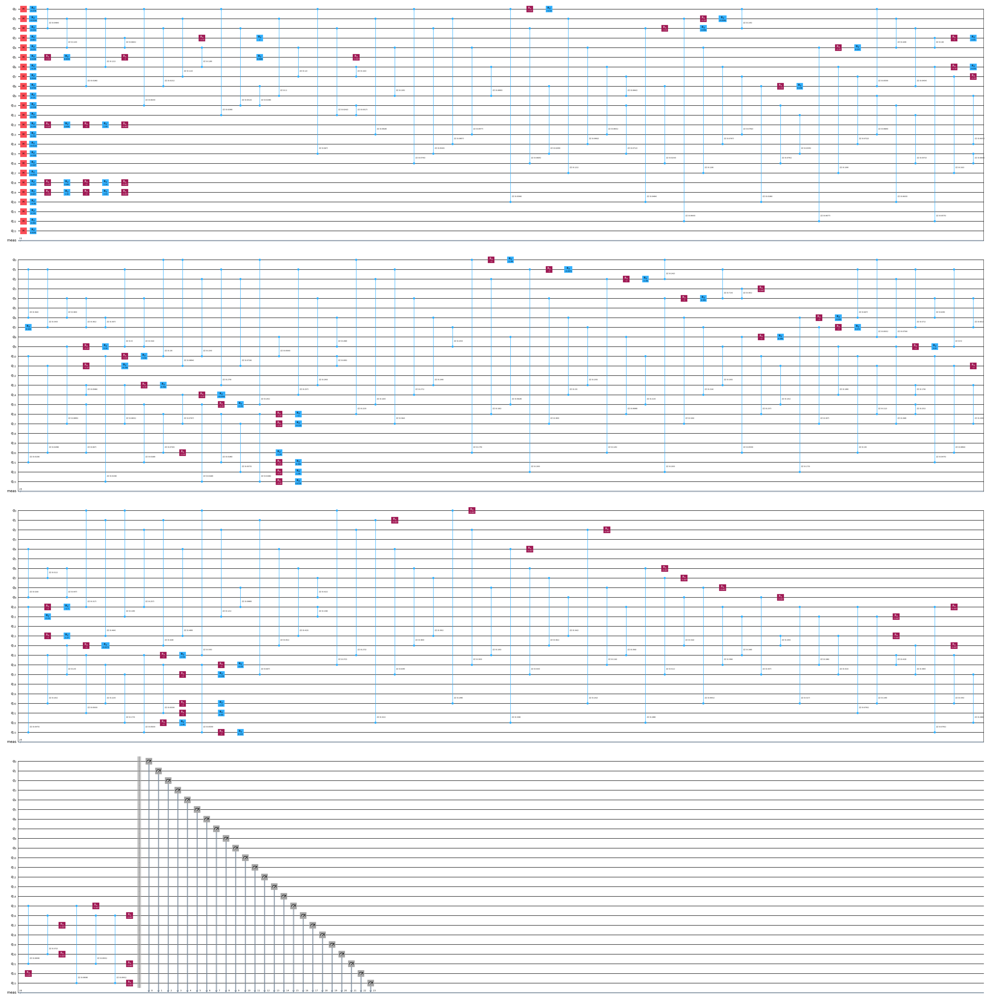


################################################################
#  PUB 1: circuits   (cap A = 27, cap B = 65)
################################################################
[PUB 1 A] ZZ gates: stayed 33/66 (50%)
[PUB 1 A] ground state of the cost: value=192 weight=27 (cap 27) feasible=True
[PUB 1 A] couplings vs biases: max|J| / max|h| = 0.224
[PUB 1 A] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.459 %   (tuner, unpruned: 0.514 %)
[PUB 1 B] ZZ gates: stayed 33/66 (50%)
[PUB 1 B] ground state of the cost: value=274 weight=56 (cap 65) feasible=True
[PUB 1 B] couplings vs biases: max|J| / max|h| = 0.278
[PUB 1 B] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.577 %   (tuner, unpruned: 1.897 %)

Logical qubits: 24 (A: 12, B: 12, no gate between the groups) | raw depth: 43 (A alone 42, B alone 39)


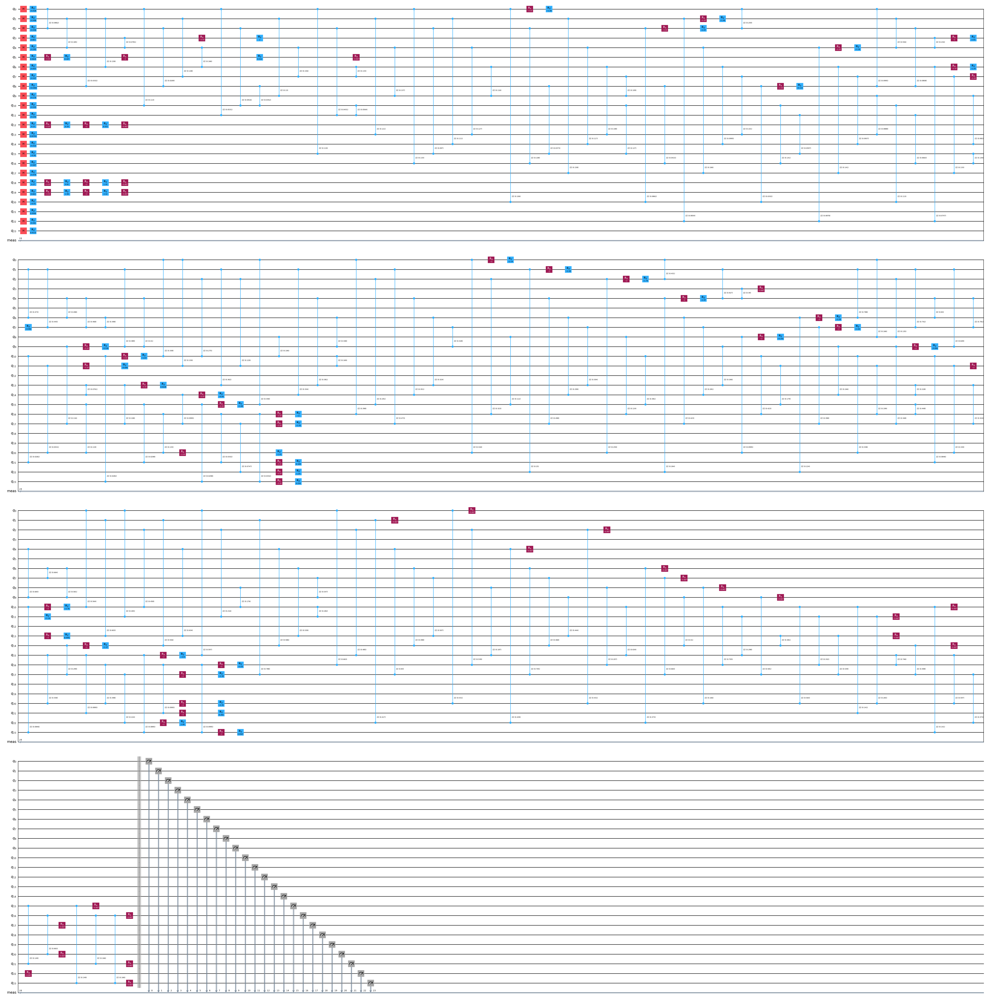


################################################################
#  PUB 2: circuits   (cap A = 36, cap B = 56)
################################################################
[PUB 2 A] ZZ gates: stayed 33/66 (50%)
[PUB 2 A] ground state of the cost: value=216 weight=33 (cap 36) feasible=True
[PUB 2 A] couplings vs biases: max|J| / max|h| = 0.205
[PUB 2 A] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 2.654 %   (tuner, unpruned: 3.071 %)
[PUB 2 B] ZZ gates: stayed 33/66 (50%)
[PUB 2 B] ground state of the cost: value=274 weight=56 (cap 56) feasible=True
[PUB 2 B] couplings vs biases: max|J| / max|h| = 0.277
[PUB 2 B] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.563 %   (tuner, unpruned: 1.897 %)

Logical qubits: 24 (A: 12, B: 12, no gate between the groups) | raw depth: 43 (A alone 42, B alone 39)


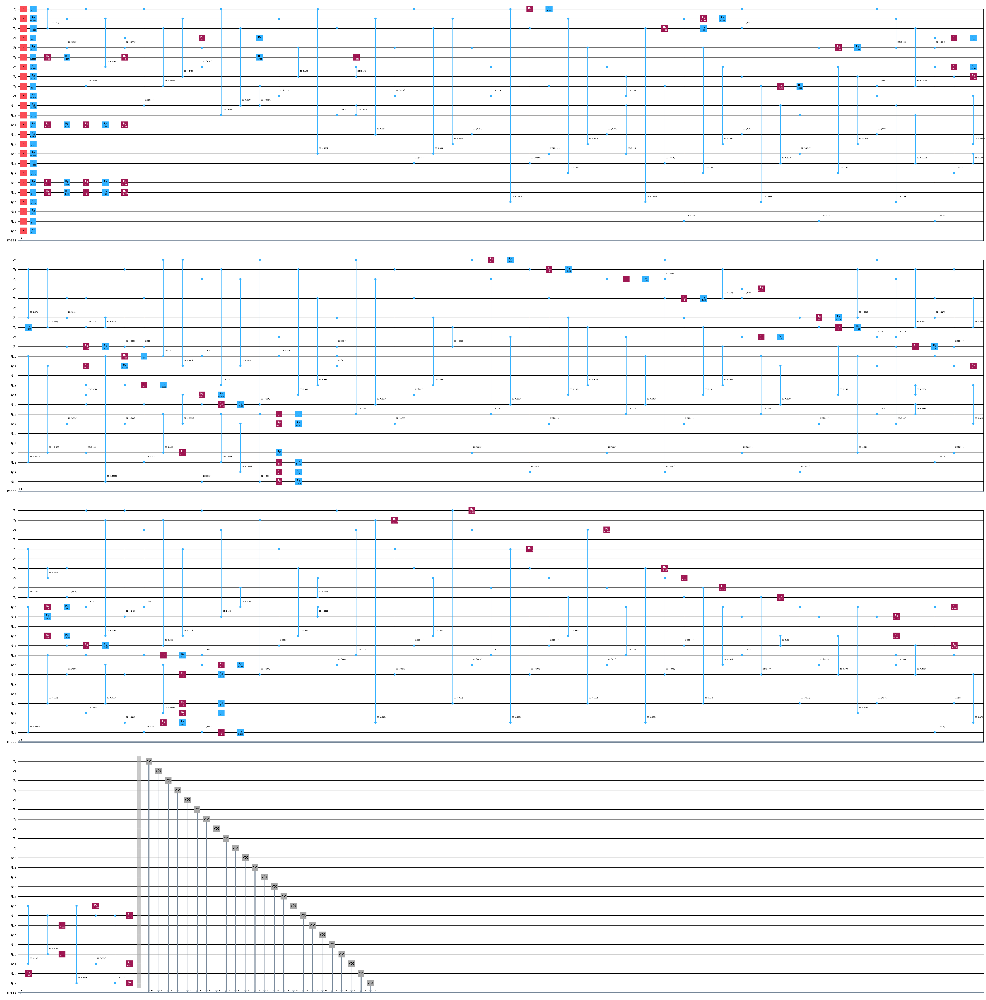


################################################################
#  PUB 3: circuits   (cap A = 45, cap B = 47)
################################################################
[PUB 3 A] ZZ gates: stayed 33/66 (50%)
[PUB 3 A] ground state of the cost: value=237 weight=43 (cap 45) feasible=True
[PUB 3 A] couplings vs biases: max|J| / max|h| = 0.353
[PUB 3 A] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.114 %   (tuner, unpruned: 0.281 %)
[PUB 3 B] ZZ gates: stayed 33/66 (50%)
[PUB 3 B] ground state of the cost: value=227 weight=43 (cap 47) feasible=True
[PUB 3 B] couplings vs biases: max|J| / max|h| = 0.293
[PUB 3 B] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.095 %   (tuner, unpruned: 0.053 %)

Logical qubits: 24 (A: 12, B: 12, no gate between the groups) | raw depth: 84 (A alone 42, B alone 83)



################################################################
#  PUB 4: circuits   (cap A = 54, cap B = 38)
################################################################
[PUB 4 A] ZZ gates: stayed 33/66 (50%)
[PUB 4 A] ground state of the cost: value=258 weight=51 (cap 54) feasible=True
[PUB 4 A] couplings vs biases: max|J| / max|h| = 0.343
[PUB 4 A] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 0.566 %   (tuner, unpruned: 0.893 %)
[PUB 4 B] ZZ gates: stayed 33/66 (50%)
[PUB 4 B] ground state of the cost: value=223 weight=36 (cap 38) feasible=True
[PUB 4 B] couplings vs biases: max|J| / max|h| = 0.176
[PUB 4 B] ideal P(opt) of the circuit that runs (PRUNE_KEEP=0.5): 1.901 %   (tuner, unpruned: 4.106 %)

Logical qubits: 24 (A: 12, B: 12, no gate between the groups) | raw depth: 43 (A alone 42, B alone 39)


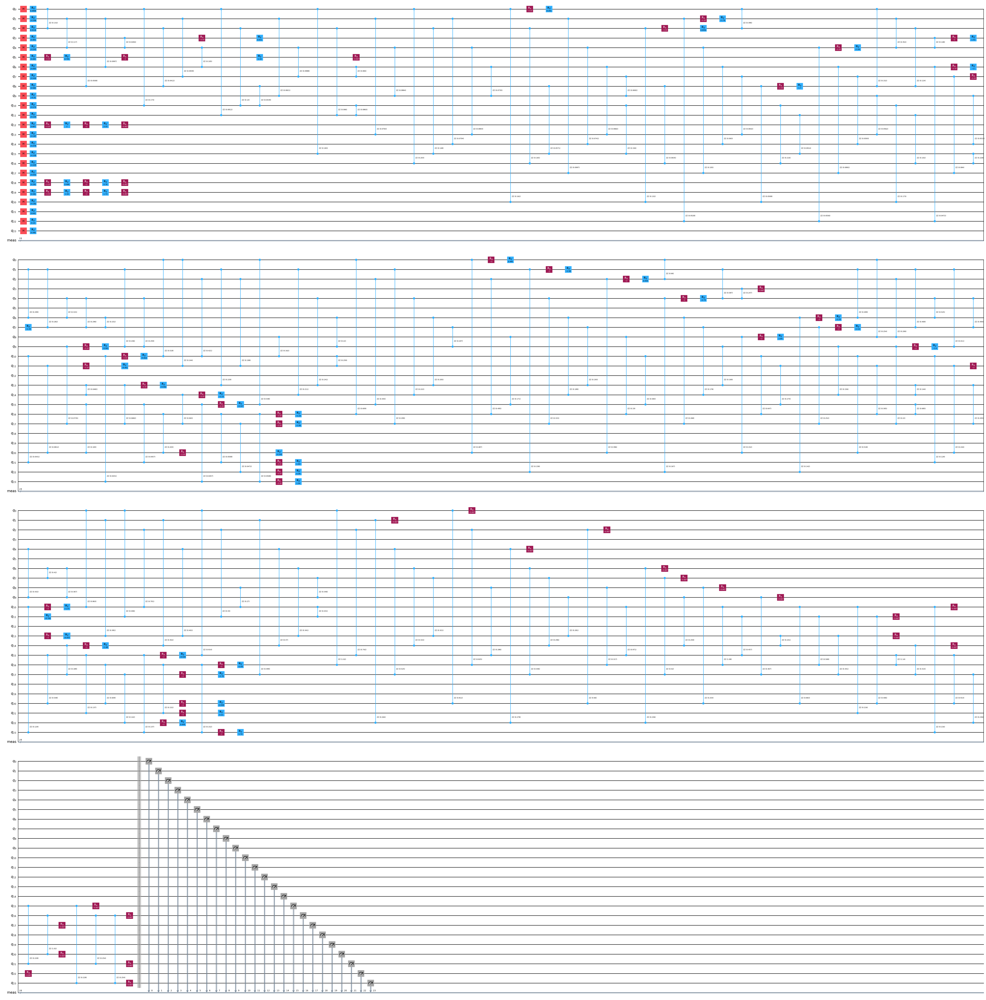

In [6]:
# ===========================================================================
# Per group: 1) QUBO by hand -> pruning -> ground-state check -> 2) Ising
#            3) digitized annealing on the group's own qubits
# Joint circuit per PUB: both groups side by side, qubit q = item q
# ===========================================================================
def show(fig):
    try:
        shell = get_ipython()
    except NameError:
        shell = None
    if shell is not None:
        from IPython.display import display
        display(fig)
        plt.close(fig)
    else:
        plt.show()


def group_circuit(vals, wts, cap, cfg, label):
    """Same construction as the N=15 notebook, on len(vals) local qubits (no measure)."""
    ALPHA, LAM1, LAM2 = cfg["ALPHA"], cfg["LAM1"], cfg["LAM2"]
    STEPS, T = cfg["STEPS"], cfg["T"]
    n = len(vals)
    lin = {j: 0.0 for j in range(n)}
    for i in range(n):
        lin[i] += -ALPHA * vals[i]
        lin[i] +=  LAM1 * wts[i]
        lin[i] +=  LAM2 * (wts[i]**2 - 2*cap*wts[i])
    raw = {}
    for i in range(n):
        for j in range(i + 1, n):
            raw[(i, j)] = 2 * LAM2 * wts[i] * wts[j]
    if PRUNE_KEEP < 1.0:
        mags = sorted(abs(v) for v in raw.values())
        cut = mags[int((1 - PRUNE_KEEP) * len(mags))]
        quad = {kk: v for kk, v in raw.items() if abs(v) >= cut}
    else:
        quad = dict(raw)
    print(f"[{label}] ZZ gates: stayed {len(quad)}/{len(raw)} ({100*len(quad)/len(raw):.0f}%)")

    _st = np.arange(1 << n); _b = (_st[:, None] >> np.arange(n)) & 1
    _V, _W = _b @ np.array(vals), _b @ np.array(wts)
    _E = -ALPHA*_V + LAM1*_W + LAM2*(_W - cap)**2
    _gs = int(np.argmin(_E))
    print(f"[{label}] ground state of the cost: value={_V[_gs]} weight={_W[_gs]} (cap {cap}) "
          f"feasible={_W[_gs] <= cap}")
    assert _W[_gs] <= cap, f"[{label}] penalty is weak - minimum is unacceptable, increase LAM1"

    h = {j: 0.0 for j in range(n)}
    J = {}
    for j in range(n):
        h[j] += -lin[j] / 2
    for (j, l), q in quad.items():
        h[j] += -q / 4
        h[l] += -q / 4
        J[(j, l)] = q / 4
    scale = max(max(abs(v) for v in h.values()), max(abs(v) for v in J.values()))
    h = {j: v / scale for j, v in h.items()}
    J = {kk: v / scale for kk, v in J.items()}
    ratio_ = max(abs(v) for v in J.values()) / max(abs(v) for v in h.values())
    print(f"[{label}] couplings vs biases: max|J| / max|h| = {ratio_:.3f}"
          + ("   WARNING: couplings almost vanish -> close to a classical threshold rule"
             if ratio_ < 0.1 else ""))

    dt = T / STEPS
    qc = QuantumCircuit(n); qc.h(range(n))
    for p in range(STEPS):
        s = (p + 0.5) / STEPS          # midpoint - mixer never drops to zero
        t_prob, t_mix = dt * s, dt * (1 - s)
        for j in range(n):
            if h[j]: qc.rz(2 * t_prob * h[j], j)
        for (j, l), Jjl in J.items():
            if Jjl: qc.rzz(2 * t_prob * Jjl, j, l)
        for j in range(n):
            qc.rx(-2 * t_mix, j)

    # ideal P(optimum) of THIS circuit (pruned) - the tuner scored the unpruned one
    _p = Statevector(qc).probabilities()
    gopt, _ = knap_dp(vals, wts, cap)
    p_run = float(_p[(_W <= cap) & (_V == gopt)].sum())
    print(f"[{label}] ideal P(opt) of the circuit that runs (PRUNE_KEEP={PRUNE_KEEP}): "
          f"{100*p_run:.3f} %   (tuner, unpruned: {100*cfg['p_opt']:.3f} %)")
    return qc, len(quad), p_run


for k, pl in enumerate(PLAN):
    print("\n" + "#" * 64)
    print(f"#  PUB {k}: circuits   (cap A = {pl['caps'][0]}, cap B = {pl['caps'][1]})")
    print("#" * 64)
    pl["local"], pl["kept_zz"], pl["p_run"] = [], [], []
    joint = QuantumCircuit(N)
    for g in range(2):
        it = GROUP_ITEMS[g]
        qc_g, kept, p_run = group_circuit([values[i] for i in it], [weights[i] for i in it],
                                          pl["caps"][g], pl["cfg"][g], f"PUB {k} {GROUP_NAMES[g]}")
        pl["local"].append(qc_g)
        pl["kept_zz"].append(kept)
        pl["p_run"].append(p_run)
        joint.compose(qc_g, qubits=it, inplace=True)       # local qubit j -> item it[j]
    joint.measure_all()
    pl["qc"] = joint
    print(f"\nLogical qubits: {N} (A: {len(GROUP_ITEMS[0])}, B: {len(GROUP_ITEMS[1])}, "
          f"no gate between the groups) | raw depth: {joint.depth()} "
          f"(A alone {pl['local'][0].depth()}, B alone {pl['local'][1].depth()})")
    if DRAW_CIRCUIT:
        show(joint.draw("mpl", fold=FOLD, idle_wires=False))

<a id="step-5"></a>
## Step 5 · Backend and noise-aware transpilation

Seed scan, layout map and ISA circuit for every PUB.

Real backend: ibm_kingston (156 qubits), use_fractional_gates=False
basis: ['cz', 'id', 'rz', 'sx', 'x', 'xslow']
rzz in basis : False
rzz in target: False

 TRANSPILATION  PUB 0  (noise-aware layout selection)

[A] Seed scan (10 transpiles), top 5 by error:
     rank    err_sum     2q   depth  seed
        1     1.5396    880     714     3
        2     1.6909    880     716     6
        3     1.7025    897     718     5
        4     1.7171    900     731     4
        5     1.7236    892     791     7
     best seed error_sum = 1.5396  (worst = 1.7670, i.e. 13% lower)

----------------------------------------------------------------
 method         err_sum  2q gates   depth
----------------------------------------------------------------
 seed-scan       1.5396       880     714
----------------------------------------------------------------
 chosen: seed-scan
 physical qubits used (20): [1, 2, 3, 4, 5, 16, 21, 22, 23, 24, 45, 46, 47, 57, 64, 65, 66, 67, 68, 77]

 logical -> physi

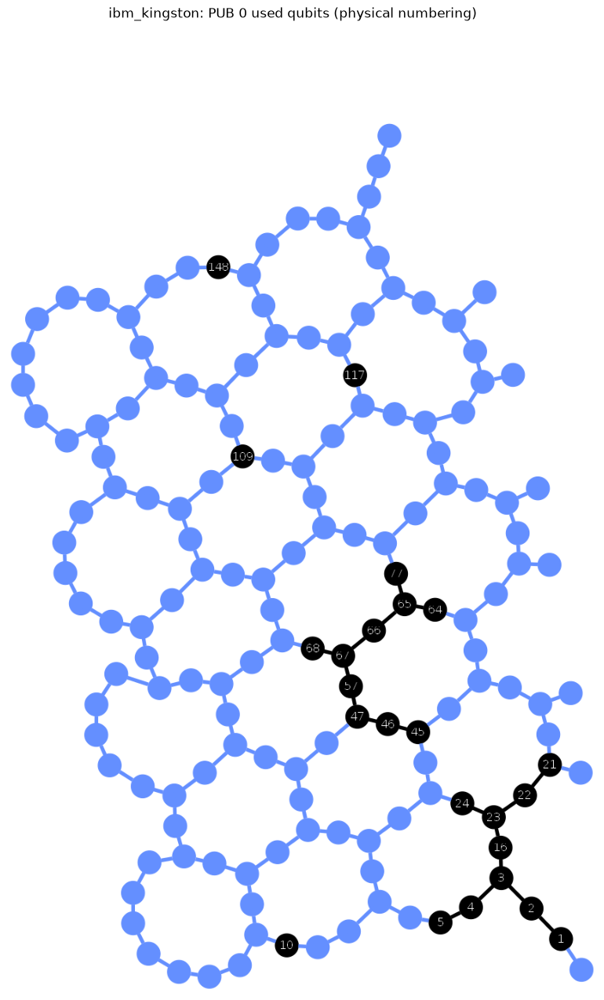

 transpiled (ISA) diagram saved: out_N24_groups\isa_pub0.png


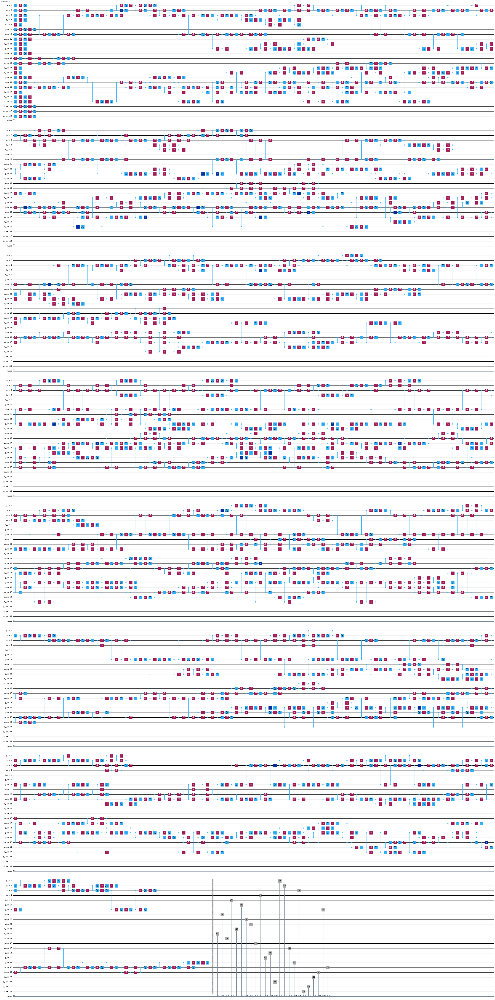

OrderedDict({'sx': 1699, 'rz': 1025, 'cz': 880, 'x': 26, 'measure': 24, 'barrier': 1})

 TRANSPILATION  PUB 1  (noise-aware layout selection)

[A] Seed scan (10 transpiles), top 5 by error:
     rank    err_sum     2q   depth  seed
        1     1.5396    880     723     3
        2     1.6909    880     719     6
        3     1.7025    897     723     5
        4     1.7171    900     726     4
        5     1.7236    892     789     7
     best seed error_sum = 1.5396  (worst = 1.7670, i.e. 13% lower)

----------------------------------------------------------------
 method         err_sum  2q gates   depth
----------------------------------------------------------------
 seed-scan       1.5396       880     723
----------------------------------------------------------------
 chosen: seed-scan
 physical qubits used (20): [1, 2, 3, 4, 5, 16, 21, 22, 23, 24, 45, 46, 47, 57, 64, 65, 66, 67, 68, 77]

 logical -> physical qubit map:
   logical  role         physical
         0  item 0 (

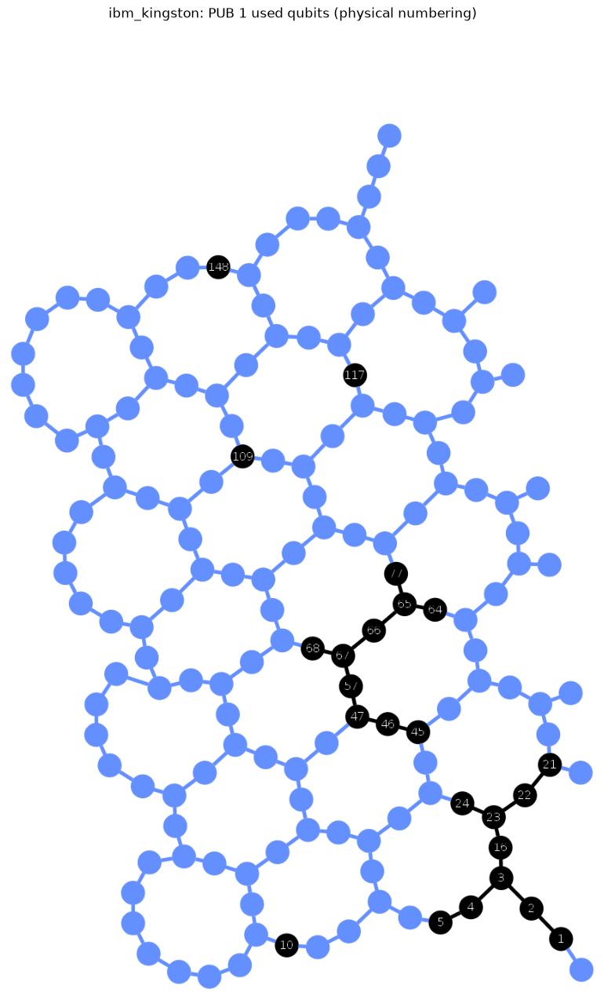

 transpiled (ISA) diagram: shown for PUB 0 only (DRAW_ISA = 'first')
OrderedDict({'sx': 1719, 'rz': 1025, 'cz': 880, 'measure': 24, 'x': 21, 'barrier': 1})

 TRANSPILATION  PUB 2  (noise-aware layout selection)

[A] Seed scan (10 transpiles), top 5 by error:
     rank    err_sum     2q   depth  seed
        1     1.5396    880     720     3
        2     1.6909    880     716     6
        3     1.7025    897     722     5
        4     1.7171    900     729     4
        5     1.7236    892     794     7
     best seed error_sum = 1.5396  (worst = 1.7670, i.e. 13% lower)

----------------------------------------------------------------
 method         err_sum  2q gates   depth
----------------------------------------------------------------
 seed-scan       1.5396       880     720
----------------------------------------------------------------
 chosen: seed-scan
 physical qubits used (20): [1, 2, 3, 4, 5, 16, 21, 22, 23, 24, 45, 46, 47, 57, 64, 65, 66, 67, 68, 77]

 logical -> physi

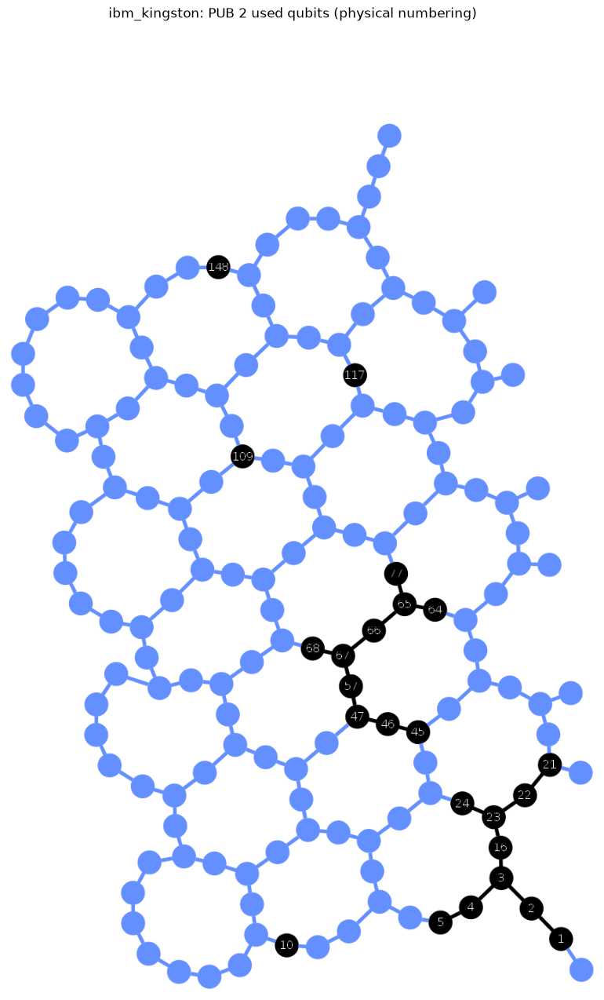

 transpiled (ISA) diagram: shown for PUB 0 only (DRAW_ISA = 'first')
OrderedDict({'sx': 1697, 'rz': 1011, 'cz': 880, 'measure': 24, 'x': 22, 'barrier': 1})

 TRANSPILATION  PUB 3  (noise-aware layout selection)

[A] Seed scan (10 transpiles), top 5 by error:
     rank    err_sum     2q   depth  seed
        1     2.4900   1551    1560     6
        2     2.7235   1580    1665     7
        3     2.7613   1538    1889     0
        4     2.7932   1527    1686     4
        5     2.8034   1563    1683     5
     best seed error_sum = 2.4900  (worst = 2.9277, i.e. 15% lower)

----------------------------------------------------------------
 method         err_sum  2q gates   depth
----------------------------------------------------------------
 seed-scan       2.4900      1551    1560
----------------------------------------------------------------
 chosen: seed-scan
 physical qubits used (20): [1, 2, 3, 4, 16, 20, 21, 22, 23, 24, 97, 105, 106, 107, 108, 109, 110, 118, 128, 129]

 logica

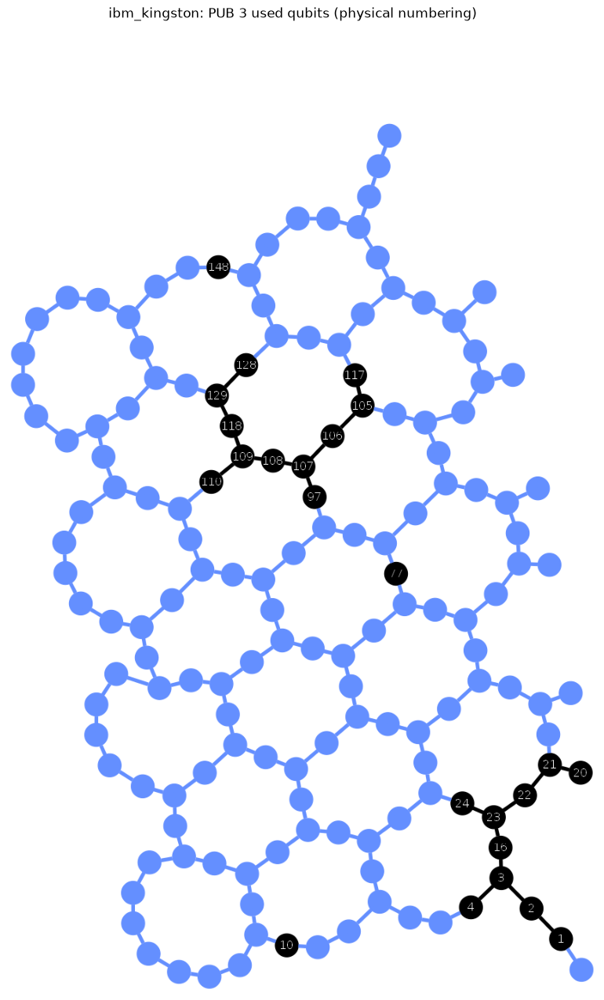

 transpiled (ISA) diagram: shown for PUB 0 only (DRAW_ISA = 'first')
OrderedDict({'sx': 2955, 'rz': 1618, 'cz': 1551, 'x': 28, 'measure': 24, 'barrier': 1})

 TRANSPILATION  PUB 4  (noise-aware layout selection)

[A] Seed scan (10 transpiles), top 5 by error:
     rank    err_sum     2q   depth  seed
        1     1.5396    880     719     3
        2     1.6909    880     713     6
        3     1.7025    897     715     5
        4     1.7171    900     731     4
        5     1.7236    892     788     7
     best seed error_sum = 1.5396  (worst = 1.7670, i.e. 13% lower)

----------------------------------------------------------------
 method         err_sum  2q gates   depth
----------------------------------------------------------------
 seed-scan       1.5396       880     719
----------------------------------------------------------------
 chosen: seed-scan
 physical qubits used (20): [1, 2, 3, 4, 5, 16, 21, 22, 23, 24, 45, 46, 47, 57, 64, 65, 66, 67, 68, 77]

 logical -> phys

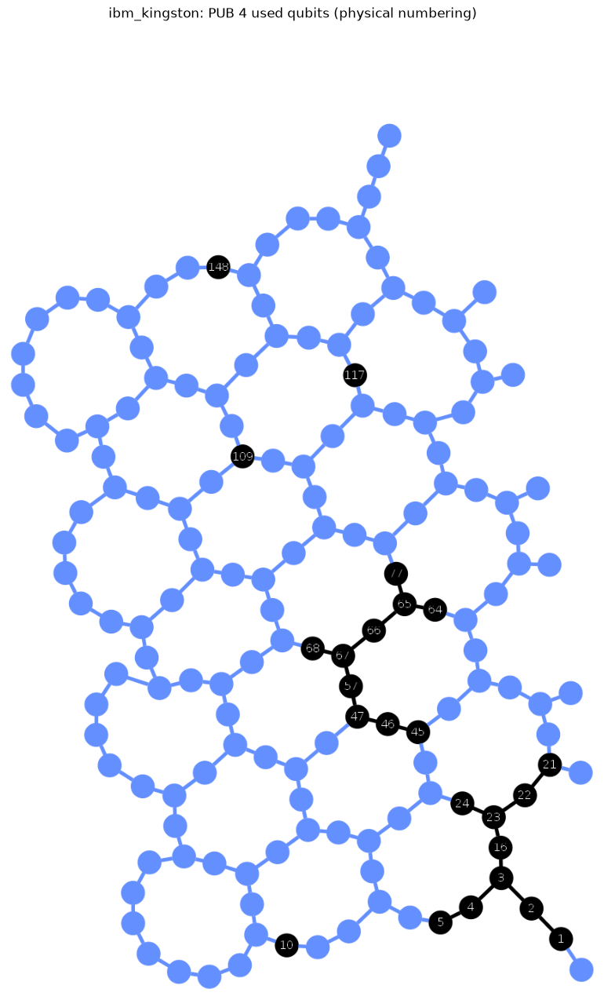

 transpiled (ISA) diagram: shown for PUB 0 only (DRAW_ISA = 'first')
OrderedDict({'sx': 1686, 'rz': 1021, 'cz': 880, 'x': 25, 'measure': 24, 'barrier': 1})

 PUB  cap A  cap B  2q gates  depth  err_sum
   0     18     74       880    714   1.5396
   1     27     65       880    723   1.5396
   2     36     56       880    720   1.5396
   3     45     47      1551   1560   2.4900
   4     54     38       880    719   1.5396


In [7]:
# ===========================================================================
# Backend
# ===========================================================================
if DRY_RUN:
    from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
    backend = FakeSherbrooke()
    print(f"[DRY_RUN] fake backend: {backend.name} ({backend.num_qubits} qubits) - "
          "used for transpilation only, sampling is ideal (no noise)")
else:
    service = QiskitRuntimeService()
    if BACKEND_NAME:
        backend = service.backend(BACKEND_NAME, use_fractional_gates=USE_FRACTIONAL_GATES)
    else:
        backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N,
                                     use_fractional_gates=USE_FRACTIONAL_GATES)
    print(f"Real backend: {backend.name} ({backend.num_qubits} qubits), "
          f"use_fractional_gates={USE_FRACTIONAL_GATES}")

print("basis:", backend.basis_gates)
print("rzz in basis :", "rzz" in backend.basis_gates)
print("rzz in target:", "rzz" in backend.target.operation_names)

target = backend.target
TWO_Q = [g for g in ("ecr", "cx", "cz", "rzz") if g in target.operation_names]


def error_score(circ):
    """Sum of 2q-gate + readout errors along the qubits the circuit actually uses
    (lower = better). One consistent metric to compare layouts."""
    s = 0.0
    for instr in circ.data:
        op = instr.operation
        qs = tuple(circ.find_bit(q).index for q in instr.qubits)
        if op.num_qubits == 2 and op.name in TWO_Q:
            pr = target[op.name].get(qs)
            if pr and pr.error is not None:
                s += pr.error
        elif op.name == "measure":
            pr = target["measure"].get(qs)
            if pr and pr.error is not None:
                s += pr.error
    return s


def twoq_count(circ):
    return sum(v for kk, v in circ.count_ops().items() if kk in TWO_Q)


# ===========================================================================
# 4A/4B) Noise-aware transpile, per PUB
# ===========================================================================
for k, pl in enumerate(PLAN):
    qc = pl["qc"]
    print("\n" + "=" * 64)
    print(f" TRANSPILATION  PUB {k}  (noise-aware layout selection)")
    print("=" * 64)

    scan = []
    for seed in range(NUM_TRANSPILES):
        pm = generate_preset_pass_manager(backend=backend, optimization_level=OPT_LEVEL,
                                          seed_transpiler=seed)
        cand = pm.run(qc)
        scan.append((error_score(cand), twoq_count(cand), cand.depth(), seed, cand))
    scan.sort(key=lambda r: r[0])

    print(f"\n[A] Seed scan ({NUM_TRANSPILES} transpiles), top 5 by error:")
    print(f"     {'rank':>4}  {'err_sum':>9}  {'2q':>5}  {'depth':>6}  {'seed':>4}")
    for rank, (sc, tq, dp_, sd, _) in enumerate(scan[:5], 1):
        print(f"     {rank:>4}  {sc:>9.4f}  {tq:>5}  {dp_:>6}  {sd:>4}")
    print(f"     best seed error_sum = {scan[0][0]:.4f}  "
          f"(worst = {scan[-1][0]:.4f}, i.e. {100*(1-scan[0][0]/scan[-1][0]):.0f}% lower)")
    candidates = [("seed-scan", scan[0][4])]

    if USE_MAPOMATIC:
        try:
            import mapomatic as mm
            base = generate_preset_pass_manager(backend=backend, optimization_level=OPT_LEVEL,
                                                seed_transpiler=0).run(qc)
            small = mm.deflate_circuit(base)
            layouts = mm.matching_layouts(small, backend)
            scored = mm.evaluate_layouts(small, layouts, backend)
            print(f"\n[B] mapomatic: {len(scored)} matching layouts on {backend.name}, top 5 by cost:")
            print(f"     {'rank':>4}  {'mm_cost':>9}  physical qubits")
            for rank, (lay, cost) in enumerate(scored[:5], 1):
                print(f"     {rank:>4}  {cost:>9.4f}  {sorted(lay)}")
            isa_mm = transpile(small, backend, initial_layout=scored[0][0],
                               optimization_level=OPT_LEVEL, seed_transpiler=0)
            candidates.append(("mapomatic", isa_mm))
        except Exception as e:
            print(f"\n[B] mapomatic skipped ({e!r})")

    print("\n" + "-" * 64)
    print(f" {'method':<12} {'err_sum':>9} {'2q gates':>9} {'depth':>7}")
    print("-" * 64)
    for name, circ in candidates:
        print(f" {name:<12} {error_score(circ):>9.4f} {twoq_count(circ):>9} {circ.depth():>7}")
    chosen, isa = min(candidates, key=lambda kv: error_score(kv[1]))
    print("-" * 64)
    print(f" chosen: {chosen}")

    phys_qubits = sorted({isa.find_bit(q).index for inst in isa.data
                          for q in inst.qubits if inst.operation.num_qubits == 2})
    print(f" physical qubits used ({len(phys_qubits)}): {phys_qubits}")
    if twoq_count(isa) > 3000:
        print(" WARNING: >3000 two-qubit gates -> expect noise. Lower N or STEPS.")

    final_layout = isa.layout.final_index_layout()      # logical k -> physical qubit
    print("\n logical -> physical qubit map:")
    print(f"   {'logical':>7}  {'role':<12} {'physical':>8}")
    for q in range(N):
        print(f"   {q:>7}  {f'item {q} ({GROUP_NAMES[GROUP_OF[q]]})':<12} {final_layout[q]:>8}")

    if MAKE_PLOTS:
        try:
            fig = plot_circuit_layout(isa, backend, view=LAYOUT_VIEW)
            fig.suptitle(f"{backend.name}: PUB {k} used qubits ({LAYOUT_VIEW} numbering)")
            show(fig)
        except Exception as e:
            print(f" layout plot skipped ({e!r})")
    if DRAW_CIRCUIT and (DRAW_ISA == "all" or (DRAW_ISA == "first" and k == 0)):
        try:
            fig = isa.draw("mpl", fold=FOLD, idle_wires=False)
            path = os.path.join(SAVE_DIR, f"isa_pub{k}.png")
            fig.savefig(path, dpi=ISA_DPI, bbox_inches="tight")
            plt.close(fig)
            print(f" transpiled (ISA) diagram saved: {path}")
            try:
                from IPython.display import Image, display
                display(Image(filename=path))
            except Exception:
                pass
        except Exception as e:
            print(f" transpiled diagram skipped ({e!r})")
    elif DRAW_CIRCUIT and DRAW_ISA == "first":
        print(" transpiled (ISA) diagram: shown for PUB 0 only (DRAW_ISA = 'first')")
    print(isa.count_ops())

    pl.update(isa=isa, chosen=chosen, twoq=twoq_count(isa), depth=isa.depth(),
              err_sum=error_score(isa), phys=phys_qubits)

print("\n" + "=" * 64)
print(f" {'PUB':>3} {'cap A':>6} {'cap B':>6} {'2q gates':>9} {'depth':>6} {'err_sum':>8}")
for k, pl in enumerate(PLAN):
    print(f" {k:>3} {pl['caps'][0]:>6} {pl['caps'][1]:>6} {pl['twoq']:>9} {pl['depth']:>6} "
          f"{pl['err_sum']:>8.4f}")

<a id="step-6"></a>
## Step 6 · Shots and the run on IBM Quantum

Shots per PUB, then one job per PUB inside a Batch, each with its job monitor and `TIME BREAKDOWN`.

In [8]:
# ===========================================================================
# MONITORING FUNCTION
# ===========================================================================
def monitor_job(job, poll_interval=10):
    status_times = {}
    current_status = None
    start_time = time.time()
    last_progress = -1

    print(f" Job ID   : {job.job_id()}")
    print(f" Backend  : {job.backend().name if hasattr(job, 'backend') else 'N/A'}")
    print(f" Started  : {time.strftime('%H:%M:%S', time.localtime(start_time))}")
    print("-" * 64)

    FINAL_STATES = {'DONE', 'FAILED', 'CANCELLED', 'ERROR'}

    try:
        while True:
            status = job.status()
            status = getattr(status, "name", status)   # IBM gives "DONE", local jobs an enum
            now = time.time()

            if status != current_status:
                if current_status is not None:
                    elapsed = now - status_times[current_status]
                    print(f"  [←] {current_status:<15} : {elapsed:>6.1f}s")
                status_times[status] = now
                current_status = status
                print(f"  [→] {status:<15} : {time.strftime('%H:%M:%S', time.localtime(now))}")

            try:
                progress = None
                if hasattr(job, 'progress') and callable(job.progress):
                    progress = job.progress()
                elif hasattr(job, 'percent_complete') and callable(job.percent_complete):
                    progress = job.percent_complete()
                if progress is not None and progress != last_progress:
                    last_progress = progress
                    bar = "█" * int(progress * 20) + " " * (20 - int(progress * 20))
                    print(f"  [▓] Progress: |{bar}| {progress*100:>5.1f}%")
            except Exception:
                pass

            if status in FINAL_STATES:
                elapsed = now - status_times[status]
                print(f"  [←] {status:<15} : {elapsed:>6.1f}s")
                break

            time.sleep(poll_interval)

    except KeyboardInterrupt:
        print("\n  [!] Monitoring stopped by user")

    print("-" * 64)
    print(" TIME BREAKDOWN:")
    total_time = time.time() - start_time
    for state, start in sorted(status_times.items(), key=lambda x: x[1]):
        end = next((v for kk, v in status_times.items() if v > start), total_time)
        if state == current_status:
            end = time.time()
        duration = end - start
        pct = 100 * duration / total_time if total_time > 0 else 0
        print(f"   {state:<15}: {duration:>6.1f}s ({pct:>5.1f}%)")

    # --- Billed usage (Pay-As-You-Go only) ---
    try:
        usage = job.usage()
        if usage:
            print(f"\n   {'Billed usage':<15}: {usage:>6.1f}s")
    except Exception:
        pass

    print(f"   {'TOTAL WALL':<15}: {total_time:>6.1f}s")
    if current_status in ('ERROR', 'FAILED', 'CANCELLED'):
        try:
            print(f"   reason         : {job.error_message()}")
        except Exception:
            pass
    print("=" * 64)
    return total_time


# ===========================================================================
# Shots per PUB
# ===========================================================================
for pl in PLAN:
    if SHOTS == "auto":
        # 10 expected hits of each group's optimum in the circuit that runs (pruned), x margin
        want = max(int(np.ceil(SHOTS_FACTOR * 10 / max(p, 1e-9))) for p in pl["p_run"])
        pl["shots_hw"] = int(min(max(want, MIN_SHOTS), MAX_SHOTS))
    else:
        pl["shots_hw"] = int(SHOTS)
    pl["shots"] = DRY_RUN_SHOTS if DRY_RUN else pl["shots_hw"]

print(f" {'PUB':>3} {'cap A':>6} {'cap B':>6} {'P(opt) A':>9} {'P(opt) B':>9} {'shots':>8} {'est. QPU':>9}")
for k, pl in enumerate(PLAN):
    print(f" {k:>3} {pl['caps'][0]:>6} {pl['caps'][1]:>6} {100*pl['p_run'][0]:>8.3f}% "
          f"{100*pl['p_run'][1]:>8.3f}% {pl['shots_hw']:>8} {pl['shots_hw'] * SECONDS_PER_SHOT:>8.0f}s")
print(" (P(opt) = ideal, pruned circuit; shots = SHOTS_FACTOR x 10 hits for the weaker group,"
      f" clipped to [{MIN_SHOTS}, {MAX_SHOTS}])")
total_hw = sum(pl["shots_hw"] for pl in PLAN)
print(f" total {total_hw} shots, est. QPU {total_hw * SECONDS_PER_SHOT:.0f} s"
      + ("   [DRY_RUN: each PUB samples %d shots ideally]" % DRY_RUN_SHOTS if DRY_RUN else ""))

# ===========================================================================
# Run
# ===========================================================================
JOB_IDS = []
if DRY_RUN:
    # ideal sampling: the groups share no gate, so each group is sampled from its own
    # statevector and the shots are joined -> 24-bit strings, qubit q = item q
    rng = np.random.default_rng(1234)
    for k, pl in enumerate(PLAN):
        full = np.zeros(pl["shots"], dtype=np.int64)
        for g in range(2):
            probs = Statevector(pl["local"][g]).probabilities()
            loc = rng.choice(len(probs), size=pl["shots"], p=probs / probs.sum())
            for j, item in enumerate(GROUP_ITEMS[g]):
                full |= ((loc >> j) & 1) << item
        vals_, cnts_ = np.unique(full, return_counts=True)
        pl["counts"] = {format(int(m), f"0{N}b"): int(c) for m, c in zip(vals_, cnts_)}
        pl["job_id"] = "dry-run"
    print("\n[DRY_RUN] sampled ideally, no job submitted")
else:
    from qiskit_ibm_runtime import Batch

    # fractional gates (rzz/rx) and gate twirling cannot be combined (IBM error 1519)
    frac = sorted({inst.operation.name for pl in PLAN for inst in pl["isa"].data}
                  & {"rzz", "rx", "rzx"})
    twirl_gates = TWIRL_GATES and not frac
    print(f"\n fractional gates in the ISA circuits: {frac or 'none'}")
    if TWIRL_GATES and frac:
        print(" -> gate twirling switched OFF (not supported with fractional gates); "
              "measurement twirling stays on")
    if frac and not USE_FRACTIONAL_GATES:
        print(" WARNING: fractional gates present although USE_FRACTIONAL_GATES = False - "
              "re-run the transpilation cell")

    def make_sampler(mode):
        s = Sampler(mode=mode)
        s.options.dynamical_decoupling.enable = DYNAMICAL_DECOUPLING
        s.options.dynamical_decoupling.sequence_type = "XY4"
        s.options.twirling.enable_gates = twirl_gates
        s.options.twirling.enable_measure = TWIRL_MEASURE
        return s

    def run_one(sampler, k, pl):
        job = sampler.run([(pl["isa"], None, pl["shots"])])
        print(f"\n===== PUB {k}  (cap A {pl['caps'][0]}, cap B {pl['caps'][1]}, "
              f"{pl['shots']} shots) =====")
        print("Job ID:", job.job_id())
        monitor_job(job, poll_interval=2)
        pl["counts"] = job.result()[0].data.meas.get_counts()
        pl["job_id"] = job.job_id()
        JOB_IDS.append(job.job_id())

    if RUN_MODE == "batch":
        try:
            batch = Batch(backend=backend)
        except Exception as e:          # only if the Batch cannot be opened at all
            batch = None
            print(f" Batch not available ({e!r}) -> jobs one by one without Batch")
        if batch is not None:
            print(f" Batch: {batch.session_id}   ({len(PLAN)} jobs, one per PUB)")
            try:
                sampler = make_sampler(batch)
                for k, pl in enumerate(PLAN):
                    run_one(sampler, k, pl)      # a failed job raises here and stops the loop
            finally:
                batch.close()
        else:
            sampler = make_sampler(backend)
            for k, pl in enumerate(PLAN):
                run_one(sampler, k, pl)
    else:   # "one_job": one job, every PUB with the same shots
        same = max(pl["shots"] for pl in PLAN)
        print(f" one job, all PUBs with {same} shots "
              f"(est. QPU {same * len(PLAN) * SECONDS_PER_SHOT:.0f} s)")
        for pl in PLAN:
            pl["shots"] = same
        sampler = make_sampler(backend)
        job = sampler.run([(pl["isa"], None, same) for pl in PLAN])
        print("\nJob ID:", job.job_id(), f"  ({len(PLAN)} PUBs, PUB index = row of the plan)")
        monitor_job(job, poll_interval=2)
        res = job.result()
        for k, pl in enumerate(PLAN):
            pl["counts"] = res[k].data.meas.get_counts()
            pl["job_id"] = job.job_id()
        JOB_IDS.append(job.job_id())

 PUB  cap A  cap B  P(opt) A  P(opt) B    shots  est. QPU
   0     18     74    4.335%    0.378%    63507       24s
   1     27     65    0.459%    0.577%    52245       20s
   2     36     56    2.654%    0.563%    42605       16s
   3     45     47    0.114%    0.095%   253205       95s
   4     54     38    0.566%    1.901%    42388       16s
 (P(opt) = ideal, pruned circuit; shots = SHOTS_FACTOR x 10 hits for the weaker group, clipped to [4000, 300000])
 total 453950 shots, est. QPU 170 s

 fractional gates in the ISA circuits: none
 Batch: 266ad0a7-97c8-4540-911a-783feea36910   (5 jobs, one per PUB)


C:\Users\pille\AppData\Local\Temp\ipykernel_82800\2065858339.py:140: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  s = Sampler(mode=mode)



===== PUB 0  (cap A 18, cap B 74, 63507 shots) =====
Job ID: dbj1i9hffo6c73b8nll0
 Job ID   : dbj1i9hffo6c73b8nll0
 Backend  : ibm_kingston
 Started  : 17:36:55
----------------------------------------------------------------
  [→] QUEUED          : 17:36:55
  [←] QUEUED          :    2.4s
  [→] RUNNING         : 17:36:58
  [←] RUNNING         :   32.2s
  [→] DONE            : 17:37:30
  [←] DONE            :    0.0s
----------------------------------------------------------------
 TIME BREAKDOWN:
   QUEUED         :    2.4s (  6.9%)
   RUNNING        :   32.2s ( 91.6%)
   DONE           :    0.0s (  0.0%)

   Billed usage   :   21.0s
   TOTAL WALL     :   35.1s

===== PUB 1  (cap A 27, cap B 65, 52245 shots) =====
Job ID: dbj1ij56p51s73cjt7ng
 Job ID   : dbj1ij56p51s73cjt7ng
 Backend  : ibm_kingston
 Started  : 17:37:32
----------------------------------------------------------------
  [→] QUEUED          : 17:37:32
  [←] QUEUED          :    2.3s
  [→] RUNNING         : 17:37:35
  [

<a id="step-7"></a>
## Step 7 · Results per PUB

`RESULT SUMMARY`, P(feasible)/P(optimum), per-group check, the most frequent bitstrings to compare with the IBM output, and both plots.


################################################################
#  PUB 0: results   (cap A = 18, cap B = 74, job dbj1i9hffo6c73b8nll0)
################################################################

                    KNAPSACK  -  RESULT SUMMARY
 Backend : ibm_kingston             Logical qubits : 24 (2 x 12)
 Method  : digitized quantum annealing (no optimizer), groups side by side
 Layout  : seed-scan   |   2q gates : 880
 PUB 0   : cap A = 18, cap B = 74, shots 63507
----------------------------------------------------------------
 Selected items
----------------------------------------------------------------
     Item  Group    Value   Weight
   ------ ------ -------- --------
        0      A       45       16
        3      B       53        8
        5      A       11        3
        8      A       49        5
       12      A       43        1
       13      B       47       13
       15      A       42       18
       18      B       22        1
       19      B       5

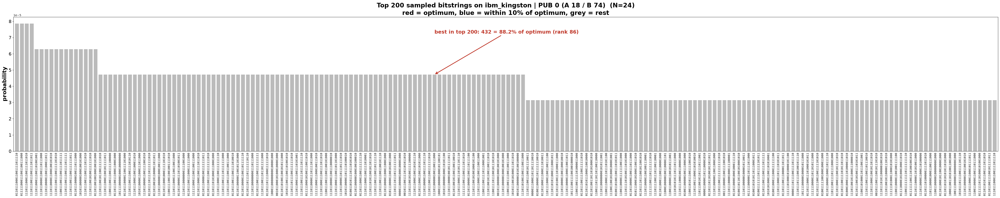

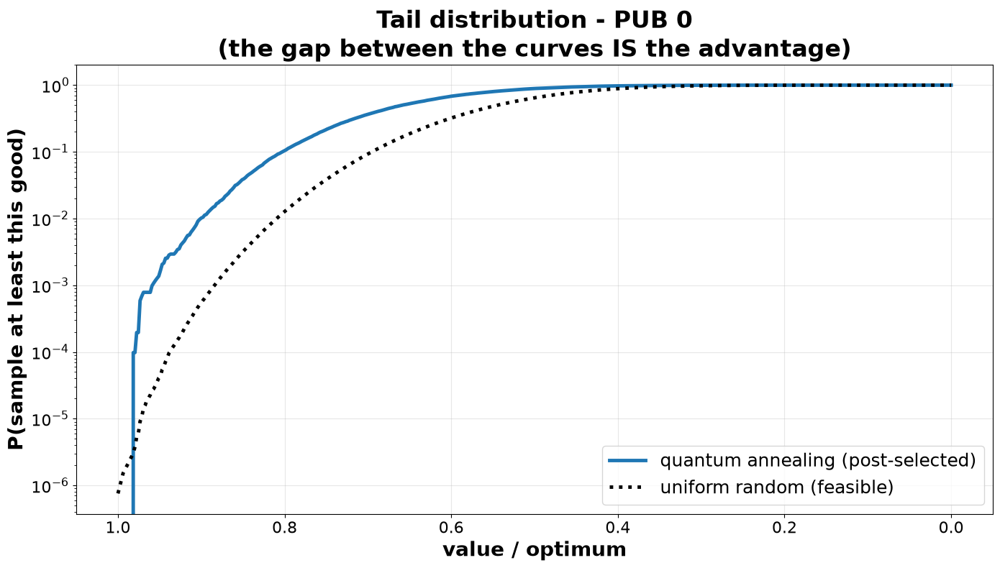


################################################################
#  PUB 1: results   (cap A = 27, cap B = 65, job dbj1ij56p51s73cjt7ng)
################################################################

                    KNAPSACK  -  RESULT SUMMARY
 Backend : ibm_kingston             Logical qubits : 24 (2 x 12)
 Method  : digitized quantum annealing (no optimizer), groups side by side
 Layout  : seed-scan   |   2q gates : 880
 PUB 1   : cap A = 27, cap B = 65, shots 52245
----------------------------------------------------------------
 Selected items
----------------------------------------------------------------
     Item  Group    Value   Weight
   ------ ------ -------- --------
        3      B       53        8
        4      B       51       20
        5      A       11        3
        8      A       49        5
       12      A       43        1
       13      B       47       13
       15      A       42       18
       18      B       22        1
       19      B       5

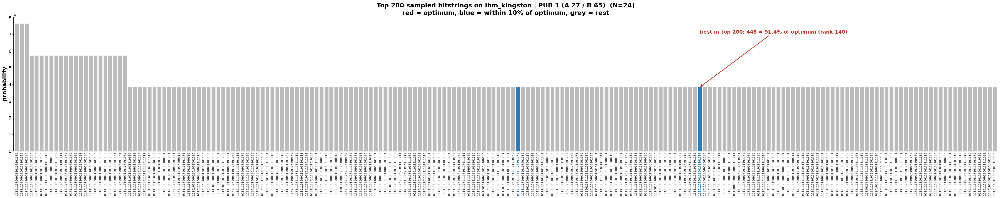

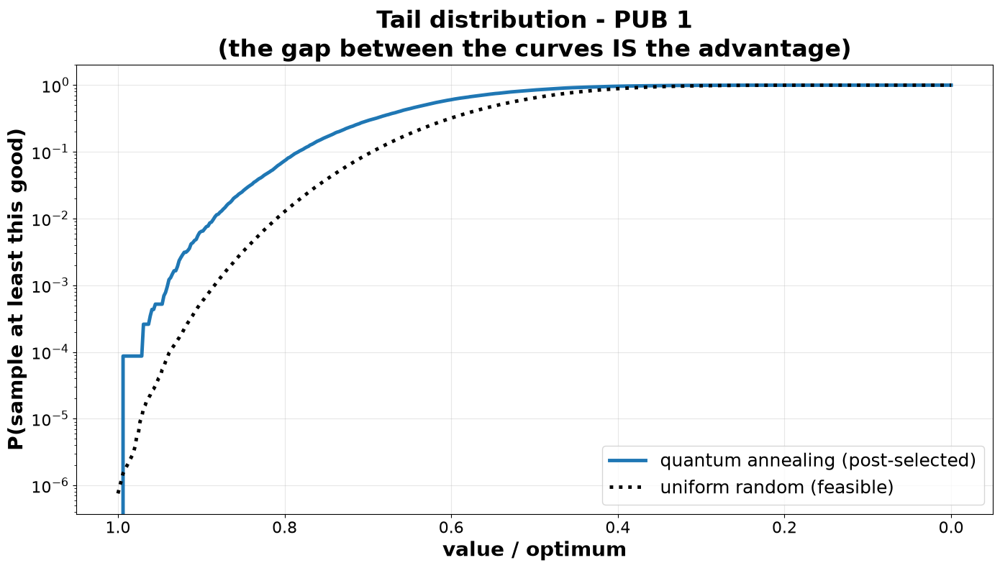


################################################################
#  PUB 2: results   (cap A = 36, cap B = 56, job dbj1j1l6p51s73cjt8u0)
################################################################

                    KNAPSACK  -  RESULT SUMMARY
 Backend : ibm_kingston             Logical qubits : 24 (2 x 12)
 Method  : digitized quantum annealing (no optimizer), groups side by side
 Layout  : seed-scan   |   2q gates : 880
 PUB 2   : cap A = 36, cap B = 56, shots 42605
----------------------------------------------------------------
 Selected items
----------------------------------------------------------------
     Item  Group    Value   Weight
   ------ ------ -------- --------
        2      A       32       13
        3      B       53        8
        4      B       51       20
        5      A       11        3
        8      A       49        5
       12      A       43        1
       13      B       47       13
       18      B       22        1
       19      B       5

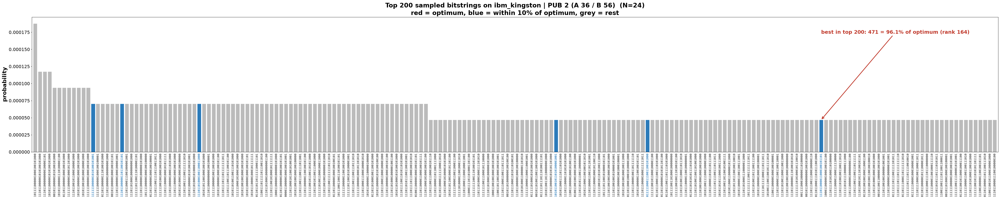

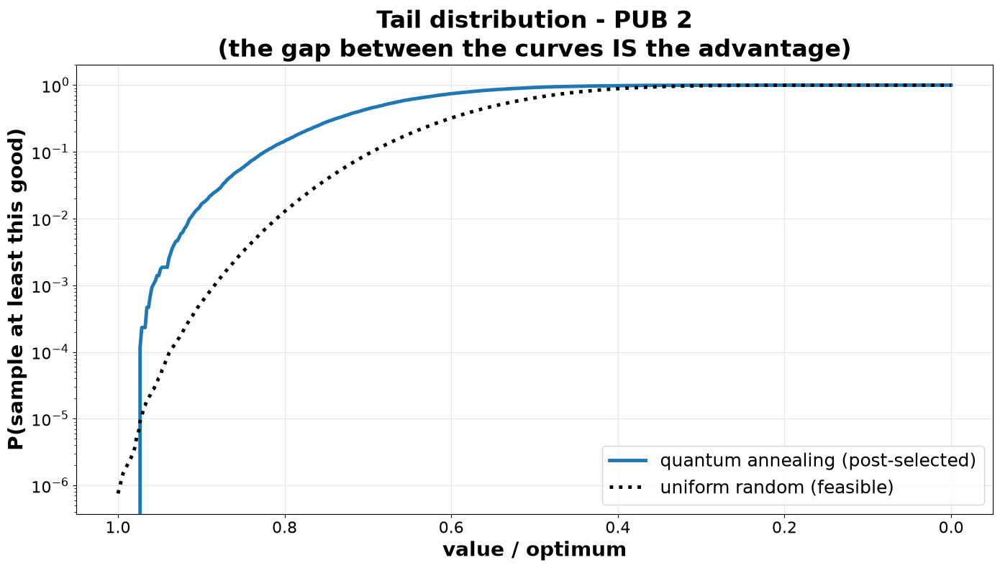


################################################################
#  PUB 3: results   (cap A = 45, cap B = 47, job dbj1j90nceqs73aj2igg)
################################################################

                    KNAPSACK  -  RESULT SUMMARY
 Backend : ibm_kingston             Logical qubits : 24 (2 x 12)
 Method  : digitized quantum annealing (no optimizer), groups side by side
 Layout  : seed-scan   |   2q gates : 1551
 PUB 3   : cap A = 45, cap B = 47, shots 253205
----------------------------------------------------------------
 Selected items
----------------------------------------------------------------
     Item  Group    Value   Weight
   ------ ------ -------- --------
        0      A       45       16
        3      B       53        8
        5      A       11        3
        8      A       49        5
       12      A       43        1
       13      B       47       13
       15      A       42       18
       18      B       22        1
       19      B      

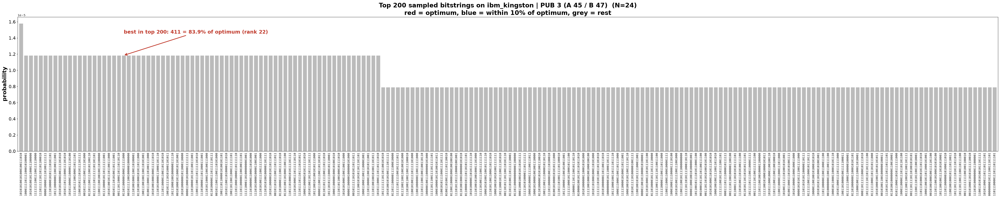

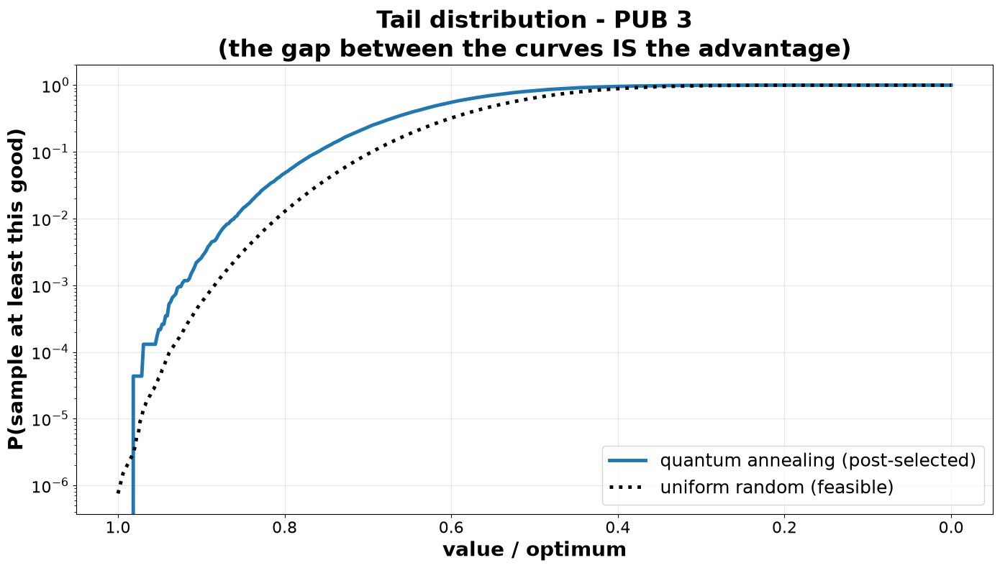


################################################################
#  PUB 4: results   (cap A = 54, cap B = 38, job dbj1kd9ffo6c73b8nr40)
################################################################

                    KNAPSACK  -  RESULT SUMMARY
 Backend : ibm_kingston             Logical qubits : 24 (2 x 12)
 Method  : digitized quantum annealing (no optimizer), groups side by side
 Layout  : seed-scan   |   2q gates : 880
 PUB 4   : cap A = 54, cap B = 38, shots 42388
----------------------------------------------------------------
 Selected items
----------------------------------------------------------------
     Item  Group    Value   Weight
   ------ ------ -------- --------
        3      B       53        8
        4      B       51       20
        5      A       11        3
        8      A       49        5
       12      A       43        1
       13      B       47       13
       15      A       42       18
       18      B       22        1
       19      B       5

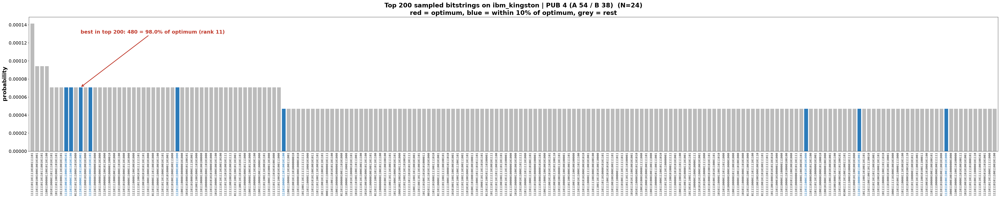

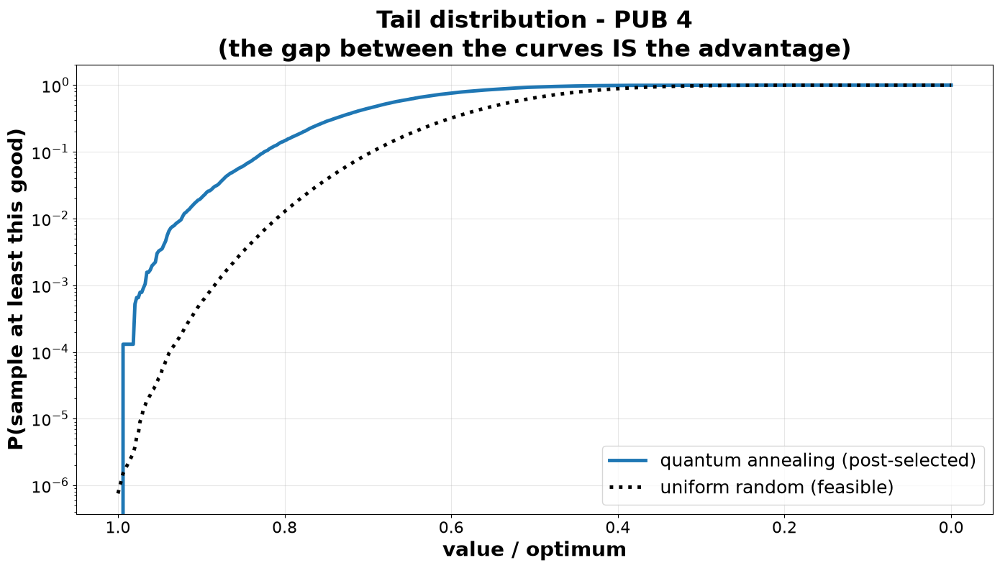

In [23]:
MAKE_PLOTS      = True
GOOD     = 0.90     # blue = within 10 % of the optimum
TOP_K    = 200      # how many of the most probable bitstrings to plot
# ===========================================================================
# Helpers: decode, distribution over the SAMPLED states, uniform reference by DP
# ===========================================================================
V_ARR, W_ARR = np.array(values), np.array(weights)
GMASK = [sum(1 << i for i in GROUP_ITEMS[g]) for g in range(2)]

# uniform-random reference without 2^24 arrays: count subsets per (weight, value)
_Wt, _Vt = int(W_ARR.sum()), int(V_ARR.sum())
_cnt = np.zeros((_Wt + 1, _Vt + 1)); _cnt[0, 0] = 1.0
for _v, _w in zip(values, weights):
    _new = _cnt.copy()
    _new[_w:, _v:] += _cnt[:_Wt + 1 - _w, :_Vt + 1 - _v]
    _cnt = _new
CNT_FEAS_BY_V = _cnt[:CAPACITY + 1].sum(axis=0)       # feasible subsets per value
N_OPT = int(CNT_FEAS_BY_V[OPT])


def decode(counts):
    keys = list(counts)
    masks = np.array([int(b.replace(" ", ""), 2) for b in keys], dtype=np.int64)
    c = np.array([counts[b] for b in keys], dtype=float)
    bits = (masks[:, None] >> np.arange(N)) & 1
    return masks, c / c.sum(), bits @ V_ARR, bits @ W_ARR, int(c.sum())


def make_dist(counts):
    masks, prob, tot_v, tot_w, shots = decode(counts)
    feas = tot_w <= CAPACITY
    return dict(masks=masks, prob=prob, tot_v=tot_v, tot_w=tot_w, feas=feas,
                good=feas & (tot_v >= GOOD * OPT), opt=feas & (tot_v == OPT), shots=shots)


def print_dist(d):
    print(f"OPT = {OPT}   optimal bitstrings: {N_OPT}")
    print(f"P(feasible) = {d['prob'][d['feas']].sum():.4f}   "
          f"P(optimum)  = {d['prob'][d['opt']].sum():.4f}   "
          f"P(within {100*(1-GOOD):.0f}%) = {d['prob'][d['good']].sum():.4f}")


def best_of(d):
    if not d["feas"].any():
        return None
    i = int(np.flatnonzero(d["feas"])[np.argmax(d["tot_v"][d["feas"]])])
    m = int(d["masks"][i])
    return [q for q in range(N) if (m >> q) & 1], int(d["tot_w"][i]), int(d["tot_v"][i]), m


def print_summary(best, header_lines, quantum_label="Quantum (hardware)"):
    print("\n" + "=" * 64)
    print("                    KNAPSACK  -  RESULT SUMMARY")
    print("=" * 64)
    for line in header_lines:
        print(line)
    if best is None:
        print("-" * 64)
        print(" No feasible solution among the samples (result dominated by noise).")
        print("=" * 64)
        return
    sel, w, v = best[0], best[1], best[2]
    print("-" * 64)
    print(" Selected items")
    print("-" * 64)
    print(f"   {'Item':>6} {'Group':>6} {'Value':>8} {'Weight':>8}")
    print(f"   {'-'*6} {'-'*6} {'-'*8} {'-'*8}")
    for i in sel:
        print(f"   {i:>6} {GROUP_NAMES[GROUP_OF[i]]:>6} {values[i]:>8} {weights[i]:>8}")
    print(f"   {'-'*6} {'-'*6} {'-'*8} {'-'*8}")
    print(f"   {'TOTAL':>6} {'':>6} {v:>8} {w:>8}    (capacity {CAPACITY})")
    print("-" * 64)
    print(" Solution quality")
    print("-" * 64)
    print(f"   {'Method':<26} {'Value':>7} {'% of optimum':>14}")
    print(f"   {'-'*26} {'-'*7} {'-'*14}")
    print(f"   {quantum_label:<26} {v:>7} {100*v/OPT:>13.1f}%")
    print(f"   {'Exact (dynamic prog.)':<26} {OPT:>7} {'-':>14}")
    print("=" * 64)


def ibm_table(counts, top=15):
    """Most frequent bitstrings exactly as the IBM output lists them."""
    d = make_dist(counts)
    order = np.argsort(-d["prob"], kind="stable")
    print(f"\n compare with the IBM output (register 'meas', item 0 = rightmost bit):")
    print(f"   {'rank':>4}  {'bitstring':<{N}}  {'count':>6}  {'value':>5}  {'weight':>6}  feasible")
    for r, i in enumerate(order[:top], 1):
        bs = format(int(d["masks"][i]), f"0{N}b")
        tag = "  <== OPTIMUM" if d["opt"][i] else ""
        print(f"   {r:>4}  {bs}  {int(round(d['prob'][i] * d['shots'])):>6}  "
              f"{int(d['tot_v'][i]):>5}  {int(d['tot_w'][i]):>6}  {str(bool(d['feas'][i])):<5}{tag}")
    hits = np.flatnonzero(d["opt"])
    if len(hits):
        for i in hits:
            r = int(np.flatnonzero(order == i)[0]) + 1
            print(f"   optimum {format(int(d['masks'][i]), f'0{N}b')} sampled "
                  f"{int(round(d['prob'][i] * d['shots']))}x, rank {r} of {len(order)}")
    else:
        print(f"   optimum {format(OPT_MASK, f'0{N}b')} not sampled in this PUB")


def plot_bitstrings(d, title_backend, fname):
    prob = d["prob"]
    order = np.argsort(-prob, kind="stable")
    top = list(order[:TOP_K])
    in_top = set(top)
    extra = [int(i) for i in np.flatnonzero(d["opt"]) if i not in in_top]   # optimum outside top-K
    rank_of = {i: int(np.flatnonzero(order == i)[0]) + 1 for i in extra}
    idx = top + extra
    ranks = list(range(1, len(top) + 1)) + [rank_of[i] for i in extra]

    FIG_W = float(np.clip(0.30 * len(idx), 14, 50))
    fig1, ax = plt.subplots(figsize=(FIG_W, 10))
    col = ["#c0392b" if d["opt"][i] else ("#2b7bba" if d["good"][i] else "#bbb") for i in idx]
    ax.bar(range(len(idx)), prob[idx], color=col, edgecolor="white", linewidth=0.5)
    ax.set_xticks(range(len(idx)))
    ax.set_xticklabels([format(int(d["masks"][i]), f"0{N}b") for i in idx],
                       rotation=90, fontsize=11, fontweight="bold", fontfamily="monospace")
    for lbl, c in zip(ax.get_xticklabels(), col):
        lbl.set_color(c if c != "#bbb" else "#444")
    ax.tick_params(axis="x", length=0, pad=6)
    ax.tick_params(axis="y", labelsize=16)
    ax.set_xlim(-0.7, len(idx) - 0.3)
    ax.set_ylabel("probability", fontsize=20, fontweight="bold")
    if extra:
        ax.axvline(len(top) - 0.5, color="#c0392b", ls="--", lw=2)
        for x, i in enumerate(extra, start=len(top)):
            ax.text(x, prob[i], f"rank {rank_of[i]}", rotation=90, ha="center", va="bottom",
                    fontsize=12, fontweight="bold", color="#c0392b")

    feas_in_view = [(x, i) for x, i in enumerate(idx) if d["feas"][i]]
    if feas_in_view:
        bx, bi = max(feas_in_view, key=lambda t: d["tot_v"][t[1]])
        where = f"top {len(top)}" if not extra else "plot"
        ax.annotate(f"best in {where}: {int(d['tot_v'][bi])} = "
                    f"{100*d['tot_v'][bi]/OPT:.1f}% of optimum (rank {ranks[bx]})",
                    xy=(bx, prob[bi]),
                    xytext=(min(bx, max(0, len(idx) - 25)), prob[idx].max() * 0.92),
                    fontsize=18, fontweight="bold", ha="left", color="#c0392b",
                    arrowprops=dict(arrowstyle="->", lw=2.5, color="#c0392b"))
    shown = f"Top {len(top)} sampled bitstrings"
    if extra:
        shown += f" + optimum (rank {', '.join(str(rank_of[i]) for i in extra)})"
    ax.set_title(f"{shown} on {title_backend}  (N={N})\n"
                 f"red = optimum, blue = within {100*(1-GOOD):.0f}% of optimum, grey = rest",
                 fontsize=22, fontweight="bold")
    plt.tight_layout()
    fig1.savefig(os.path.join(SAVE_DIR, fname), dpi=110, bbox_inches="tight")
    show(fig1)


def plot_tail(d, title_extra, fname):
    p_feas = d["prob"][d["feas"]].sum()
    if p_feas <= 0:
        print(" tail plot skipped (P(feasible) = 0)")
        return
    pv = np.bincount(d["tot_v"][d["feas"]], weights=d["prob"][d["feas"]], minlength=_Vt + 1)
    cum_q_all = np.cumsum(pv[::-1])[::-1] / p_feas
    cum_r_all = np.cumsum(CNT_FEAS_BY_V[::-1])[::-1] / CNT_FEAS_BY_V.sum()
    vals_sorted = np.flatnonzero(CNT_FEAS_BY_V)[::-1]
    fig2, ax2 = plt.subplots(figsize=(14, 8))
    ax2.plot(vals_sorted / OPT, cum_q_all[vals_sorted], lw=3.5,
             label="quantum annealing (post-selected)")
    ax2.plot(vals_sorted / OPT, cum_r_all[vals_sorted], "k:", lw=3.5,
             label="uniform random (feasible)")
    ax2.set_xlabel("value / optimum", fontsize=20, fontweight="bold")
    ax2.set_ylabel("P(sample at least this good)", fontsize=20, fontweight="bold")
    ax2.tick_params(labelsize=16)
    ax2.set_yscale("log"); ax2.invert_xaxis()
    ax2.set_title(f"Tail distribution {title_extra}\n(the gap between the curves IS the advantage)",
                  fontsize=24, fontweight="bold")
    ax2.legend(fontsize=18); ax2.grid(alpha=.3)
    plt.tight_layout()
    fig2.savefig(os.path.join(SAVE_DIR, fname), dpi=110, bbox_inches="tight")
    show(fig2)


def group_check(counts, caps):
    """Per group: its own optimum at its capacity, and the best sampled part."""
    masks, prob, _, _, shots = decode(counts)
    print(f"\n   {'group':>5} {'cap':>5} {'group opt':>9} {'best sampled':>12} {'P(group opt)':>12}")
    for g in range(2):
        it = GROUP_ITEMS[g]
        gopt, _ = knap_dp([values[i] for i in it], [weights[i] for i in it], caps[g])
        sub = masks & GMASK[g]
        bits = (sub[:, None] >> np.arange(N)) & 1
        gv, gw = bits @ V_ARR, bits @ W_ARR
        ok = gw <= caps[g]
        best = int(gv[ok].max()) if ok.any() else 0
        p_hit = float(prob[ok & (gv == gopt)].sum())
        print(f"   {GROUP_NAMES[g]:>5} {caps[g]:>5} {gopt:>9} {best:>12} {p_hit:>12.4f}"
              + ("   hit" if best == gopt else ""))


# ===========================================================================
# Results per PUB
# ===========================================================================
for k, pl in enumerate(PLAN):
    print("\n" + "#" * 64)
    print(f"#  PUB {k}: results   (cap A = {pl['caps'][0]}, cap B = {pl['caps'][1]}, "
          f"job {pl['job_id']})")
    print("#" * 64)
    d = make_dist(pl["counts"])
    pl["dist"] = d
    best = best_of(d)
    pl["best"] = best
    print_summary(best, [
        f" Backend : {backend.name:<24} Logical qubits : {N} (2 x {N//2})",
        f" Method  : digitized quantum annealing (no optimizer), groups side by side",
        f" Layout  : {pl['chosen']}   |   2q gates : {pl['twoq']}",
        f" PUB {k}   : cap A = {pl['caps'][0]}, cap B = {pl['caps'][1]}, shots {d['shots']}",
    ], "Quantum, best single shot")
    print_dist(d)
    group_check(pl["counts"], pl["caps"])
    ibm_table(pl["counts"])
    if MAKE_PLOTS:
        plot_bitstrings(d, f"{backend.name} | PUB {k} (A {pl['caps'][0]} / B {pl['caps'][1]})",
                        f"bitstrings_pub{k}.png")
        plot_tail(d, f"- PUB {k}", f"tail_pub{k}.png")

<a id="step-8"></a>
## Step 8 · Classical reconstruction of the global solution

All PUBs together, the best combination of group-A and group-B parts with total weight ≤ C, and all counts saved to JSON.


################################################################
#  ALL 5 PUBs TOGETHER
################################################################

                    KNAPSACK  -  RESULT SUMMARY
 Backend : ibm_kingston             Logical qubits : 24 (2 x 12)
 Method  : digitized quantum annealing, 5 PUBs, groups side by side
 Shots   : 453950 in total
----------------------------------------------------------------
 Selected items
----------------------------------------------------------------
     Item  Group    Value   Weight
   ------ ------ -------- --------
        3      B       53        8
        4      B       51       20
        5      A       11        3
        8      A       49        5
       12      A       43        1
       13      B       47       13
       15      A       42       18
       18      B       22        1
       19      B       50        5
       21      A       44        4
       22      B       51        9
       23      A       24        4
 

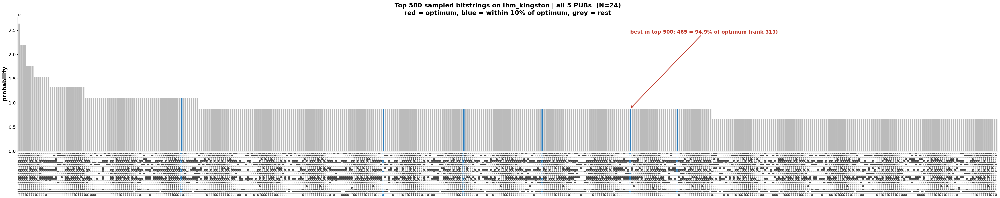

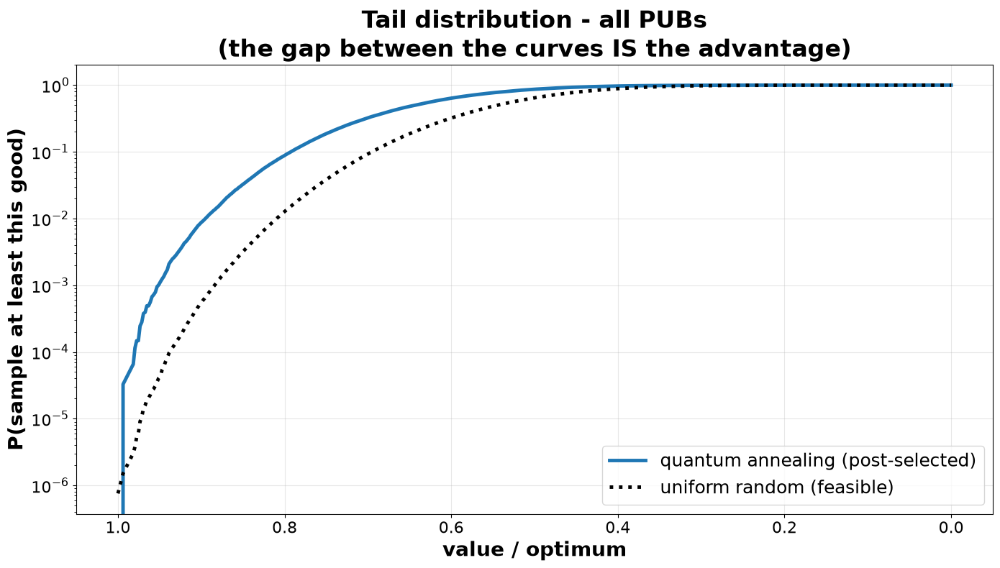


          KNAPSACK  -  COMBINED GROUPS (classical step)
     Item  Group    Value   Weight  part sampled in PUB
   ------ ------ -------- --------  -------------------
        0      A       45       16  0,1,2,3,4
        3      B       53        8  0,1,2,3,4
        4      B       51       20  0,1,2,3,4
        5      A       11        3  0,1,2,3,4
        8      A       49        5  0,1,2,3,4
       12      A       43        1  0,1,2,3,4
       13      B       47       13  0,1,2,3,4
       18      B       22        1  0,1,2,3,4
       19      B       50        5  0,1,2,3,4
       21      A       44        4  0,1,2,3,4
       22      B       51        9  0,1,2,3,4
       23      A       24        4  0,1,2,3,4
   ------ ------ -------- --------
    TOTAL             490       89    (capacity 92)
   bitstring: 111011000011000100111001
----------------------------------------------------------------
   Method                           Value   % of optimum
   ----------------------------

In [18]:
# ===========================================================================
# All PUBs together: raw joint bitstrings
# ===========================================================================
ALL_COUNTS = {}
for pl in PLAN:
    for b, c in pl["counts"].items():
        ALL_COUNTS[b] = ALL_COUNTS.get(b, 0) + c
d_all = make_dist(ALL_COUNTS)
best_shot = best_of(d_all)
print("\n" + "#" * 64)
print(f"#  ALL {len(PLAN)} PUBs TOGETHER")
print("#" * 64)
print_summary(best_shot, [
    f" Backend : {backend.name:<24} Logical qubits : {N} (2 x {N//2})",
    f" Method  : digitized quantum annealing, {len(PLAN)} PUBs, groups side by side",
    f" Shots   : {d_all['shots']} in total",
], "Quantum, best single shot")
print_dist(d_all)
if MAKE_PLOTS:
    plot_bitstrings(d_all, f"{backend.name} | all {len(PLAN)} PUBs", "bitstrings_all.png")
    plot_tail(d_all, "- all PUBs", "tail_all.png")

# ===========================================================================
# Combining the groups: best part of A + best part of B over ALL PUBs, total <= C
# ===========================================================================
pareto = [{}, {}]           # per group: weight -> (value, part mask)
seen_in = {}                # (group, part mask) -> PUBs where that exact part was sampled
for k, pl in enumerate(PLAN):
    masks = np.array([int(b.replace(" ", ""), 2) for b in pl["counts"]], dtype=np.int64)
    for g in range(2):
        sub = np.unique(masks & GMASK[g])
        bits = (sub[:, None] >> np.arange(N)) & 1
        for m, v, w in zip(sub, bits @ V_ARR, bits @ W_ARR):
            seen_in.setdefault((g, int(m)), []).append(k)
            if w <= CAPACITY and (w not in pareto[g] or v > pareto[g][w][0]):
                pareto[g][int(w)] = (int(v), int(m))

combo = None
for wa, (va, ma) in pareto[0].items():
    for wb, (vb, mb) in pareto[1].items():
        if wa + wb <= CAPACITY and (combo is None or va + vb > combo[0]):
            combo = (va + vb, wa + wb, ma | mb,
                     ",".join(map(str, seen_in[(0, ma)])), ",".join(map(str, seen_in[(1, mb)])))

print("\n" + "=" * 64)
print("          KNAPSACK  -  COMBINED GROUPS (classical step)")
print("=" * 64)
if combo is None:
    print(" no feasible parts sampled")
else:
    v, w, m, ka, kb = combo
    sel = [q for q in range(N) if (m >> q) & 1]
    print(f"   {'Item':>6} {'Group':>6} {'Value':>8} {'Weight':>8}  part sampled in PUB")
    print(f"   {'-'*6} {'-'*6} {'-'*8} {'-'*8}  {'-'*19}")
    for i in sel:
        print(f"   {i:>6} {GROUP_NAMES[GROUP_OF[i]]:>6} {values[i]:>8} {weights[i]:>8}  "
              f"{ka if GROUP_OF[i] == 0 else kb}")
    print(f"   {'-'*6} {'-'*6} {'-'*8} {'-'*8}")
    print(f"   {'TOTAL':>6} {'':>6} {v:>8} {w:>8}    (capacity {CAPACITY})")
    print(f"   bitstring: {format(m, f'0{N}b')}")
print("-" * 64)
print(f"   {'Method':<30} {'Value':>7} {'% of optimum':>14}")
print(f"   {'-'*30} {'-'*7} {'-'*14}")
if best_shot:
    print(f"   {'Quantum, best single shot':<30} {best_shot[2]:>7} {100*best_shot[2]/OPT:>13.1f}%")
if combo:
    print(f"   {'Quantum + combining groups':<30} {combo[0]:>7} {100*combo[0]/OPT:>13.1f}%")
print(f"   {'Exact (dynamic prog.)':<30} {OPT:>7} {'-':>14}")
print("=" * 64)

# why the combination did or did not reach the optimum
print("\n parts of the optimum vs. what the groups sampled:")
for g in range(2):
    part = [i for i in OPT_SEL if GROUP_OF[i] == g]
    pw, pv = sum(weights[i] for i in part), sum(values[i] for i in part)
    got = max((v_ for w_, (v_, _) in pareto[g].items() if w_ <= pw), default=0)
    print(f"   group {GROUP_NAMES[g]}: optimum part weight {pw:>4} value {pv:>4} | best sampled "
          f"part with weight <= {pw}: {got:>4}  {'OK' if got >= pv else 'MISSING'}")

# ===========================================================================
# Save everything for later comparison with the IBM output
# ===========================================================================
payload = {
    "values": values, "weights": weights, "capacity": CAPACITY,
    "optimum": OPT, "optimal_items": OPT_SEL, "optimal_bitstring": format(OPT_MASK, f"0{N}b"),
    "groups": {GROUP_NAMES[g]: GROUP_ITEMS[g] for g in range(2)},
    "backend": backend.name, "dry_run": DRY_RUN, "job_ids": JOB_IDS,
    "pubs": [{
        "pub": k, "caps": pl["caps"], "shift": pl["shift"], "shots": pl["shots"],
        "job_id": pl["job_id"], "twoq": pl["twoq"], "depth": pl["depth"],
        "penalties": [{**{kk: pl["cfg"][g][kk] for kk in ("ALPHA", "LAM1", "LAM2", "STEPS", "T",
                                                         "p_opt", "shots_for_10_hits")},
                       "p_opt_pruned_ideal": pl["p_run"][g]}
                      for g in range(2)],
        "best_single_shot": pl["best"][2] if pl["best"] else None,
        "counts": pl["counts"],
    } for k, pl in enumerate(PLAN)],
    "best_single_shot": best_shot[2] if best_shot else None,
    "combined": combo[0] if combo else None,
}
fname = os.path.join(SAVE_DIR, f"counts_N{N}_{'dryrun' if DRY_RUN else backend.name}.json")
with open(fname, "w") as f:
    json.dump(payload, f, default=float)
print(f"\n saved: {fname}   (plots in {SAVE_DIR}/)")

<a id="step-9"></a>
## Step 9 · Fair test against random sampling

Reconstruction from only the K most frequent parts of each group, run identically on uniformly random bitstrings as a control.

In [24]:
"""Fair test of combining the groups: use only the K MOST FREQUENT parts of each group,
and run exactly the same procedure on uniformly random bitstrings (control) with the
same number of shots. Prints what the combined solution is made of."""
import json
import random
import sys
from collections import Counter

path = "out_N24_groups/counts_N24_ibm_kingston.json"
d = json.load(open(path))
v, w, C, N = d["values"], d["weights"], d["capacity"], len(d["values"])
GN = list(d["groups"].keys())                       # ["A", "B"]
groups = list(d["groups"].values())
gmask = [sum(1 << i for i in g) for g in groups]
OPT = d["optimum"]
opt_part = [sum(1 << i for i in d["optimal_items"] if i in g) for g in groups]
rng = random.Random(7)
KS = (1, 5, 10, 25, 50, 100)

def val(m): return sum(v[i] for i in range(N) if m >> i & 1)
def wt(m):  return sum(w[i] for i in range(N) if m >> i & 1)
def items(m): return [i for i in range(N) if m >> i & 1]
def bs(m): return format(m, f"0{N}b")

def subsample(counts, shots):
    """Draw `shots` shots from the measured distribution (counts keep no shot order)."""
    keys = list(counts)
    if shots is None or shots >= sum(counts.values()):
        return Counter({int(k, 2): c for k, c in counts.items()})
    return Counter(int(k, 2) for k in rng.choices(keys, weights=[counts[k] for k in keys], k=shots))

def random_shots(n):
    return Counter(rng.getrandbits(N) for _ in range(n))

def group_parts(samples, g):
    c = Counter()
    for m, n in samples.items():
        c[m & gmask[g]] += n
    return c

def rank(c, part):
    order = [m for m, _ in c.most_common()]
    return order.index(part) + 1 if part in c else None

def combine_topk(parts, K):
    """Best pair among the K most frequent parts of each group: (value, mask A, mask B)."""
    best = (0, None, None)
    for ma, _ in parts[0].most_common(K):
        for mb, _ in parts[1].most_common(K):
            if wt(ma | mb) <= C and val(ma | mb) > best[0]:
                best = (val(ma | mb), ma, mb)
    return best

def describe(label, best, pooled, per_pub_parts, K):
    """What the combined solution is made of."""
    value, ma, mb = best
    print(f"\n   {label}, K={K}: {value} = {100*value/OPT:.1f} % of optimum"
          + ("   <== OPTIMUM" if value == OPT else ""))
    if ma is None:
        print("      no feasible pair")
        return
    for g, m in ((0, ma), (1, mb)):
        tag = "  (= part of the optimum)" if m == opt_part[g] else ""
        print(f"      group {GN[g]}: items {items(m)}  weight {wt(m)}  value {val(m)}{tag}")
        print(f"               bits {bs(m)}")
        print(f"               rank {rank(pooled[g], m)} of the {len(pooled[g])} sampled parts "
              f"(all PUBs), {pooled[g][m]} shots;  per PUB: "
              + ", ".join(f"PUB {k}: {pp[g][m]}x rank {rank(pp[g], m)}"
                          for k, pp in enumerate(per_pub_parts) if pp[g][m]))
    print(f"      combined: items {items(ma | mb)}  weight {wt(ma | mb)}/{C}  value {value}")
    print(f"               bits {bs(ma | mb)}")

def report(label, per_pub):
    pooled = [Counter(), Counter()]
    per_pub_parts = []
    print(f"\n--- {label}")
    print(f"   {'PUB':>4} {'shots':>7} {'rank opt part A':>16} {'rank opt part B':>16}   (of 4096 states)")
    for k, s in enumerate(per_pub):
        parts = [group_parts(s, g) for g in range(2)]
        per_pub_parts.append(parts)
        for g in range(2):
            pooled[g].update(parts[g])
        print(f"   {k:>4} {sum(s.values()):>7} {str(rank(parts[0], opt_part[0])):>16} "
              f"{str(rank(parts[1], opt_part[1])):>16}")
    res = {K: combine_topk(pooled, K) for K in KS}
    print("   combine top-K parts of each group (all PUBs pooled):  "
          + "  ".join(f"K={K}: {res[K][0]}{'*' if res[K][0] == OPT else ''}" for K in KS))
    print(f"   optimum parts in the pooled ranking: A rank {rank(pooled[0], opt_part[0])}, "
          f"B rank {rank(pooled[1], opt_part[1])}  -> smallest K that can reach the optimum: "
          f"{max(rank(pooled[0], opt_part[0]) or 10**9, rank(pooled[1], opt_part[1]) or 10**9)}")
    return res, pooled, per_pub_parts

for shots in (None, 2000):
    tag = "all shots" if shots is None else f"{shots} shots per PUB (subsampled)"
    hw = [subsample(p["counts"], shots) for p in d["pubs"]]
    rnd = [random_shots(sum(s.values())) for s in hw]
    print("\n" + "=" * 78)
    print(f" {tag}   - optimum {OPT}, * = combination reached it")
    print("=" * 78)
    res_h, pool_h, pp_h = report(f"hardware ({d['backend']})", hw)
    res_r, pool_r, pp_r = report("control: uniformly random bitstrings, same shots", rnd)

    # what the combination is made of: smallest K where the hardware reaches the optimum
    k_hit = next((K for K in KS if res_h[K][0] == OPT), KS[-1])
    print(f"\n   WHAT IT IS MADE OF  (K = {k_hit}, the smallest tested K where the hardware "
          f"reaches the optimum)")
    describe("hardware", res_h[k_hit], pool_h, pp_h, k_hit)
    describe("control ", res_r[k_hit], pool_r, pp_r, k_hit)


 all shots   - optimum 490, * = combination reached it

--- hardware (ibm_kingston)
    PUB   shots  rank opt part A  rank opt part B   (of 4096 states)
      0   63507                7              131
      1   52245                2               16
      2   42605                4               31
      3  253205                3              475
      4   42388               22               10
   combine top-K parts of each group (all PUBs pooled):  K=1: 347  K=5: 439  K=10: 443  K=25: 490*  K=50: 490*  K=100: 490*
   optimum parts in the pooled ranking: A rank 2, B rank 16  -> smallest K that can reach the optimum: 16

--- control: uniformly random bitstrings, same shots
    PUB   shots  rank opt part A  rank opt part B   (of 4096 states)
      0   63507             3868              201
      1   52245             3923              796
      2   42605             1316              508
      3  253205                5              128
      4   42388             1133           

<a id="step-10"></a>
## Step 10 · Blind reconstruction

Finds the best solution without knowing the optimum; prints the first K at which it appears and the IBM shots it comes from.

In [26]:
"""Blind combination: compose the best solution from the measured shots WITHOUT knowing
the optimum. Only the K most frequent parts of each group are used (the circuit acts as
the filter). K grows from 1 to K_MAX; every improvement is printed, so the first K at
which the final answer appears is visible. The optimum (DP) is used only in the separate
VERIFY block at the end, which can be switched off."""
import json
from collections import Counter

path   = "out_N24_groups/counts_N24_ibm_kingston.json"
K_MAX  = 25        # fix this BEFORE looking at the result of a new run
VERIFY = True      # compare with the exact optimum afterwards (evaluation only)

d = json.load(open(path))
v, w, C, N = d["values"], d["weights"], d["capacity"], len(d["values"])
GN = list(d["groups"].keys())
groups = list(d["groups"].values())
gmask = [sum(1 << i for i in g) for g in groups]

def val(m): return sum(v[i] for i in range(N) if m >> i & 1)
def wt(m):  return sum(w[i] for i in range(N) if m >> i & 1)
def items(m): return [i for i in range(N) if m >> i & 1]
def bs(m): return format(m, f"0{N}b")

# parts of each group, pooled over all PUBs (= all jobs), ranked by frequency
shots_of = [Counter(), Counter()]
pubs_of = [{}, {}]
for p in d["pubs"]:
    for b, n in p["counts"].items():
        m = int(b, 2)
        for g in range(2):
            part = m & gmask[g]
            shots_of[g][part] += n
            pubs_of[g].setdefault(part, Counter())[p["pub"]] += n
ranked = [[m for m, _ in shots_of[g].most_common()] for g in range(2)]

# LP upper bound: no solution can be better than this (no knowledge of the optimum needed)
order = sorted(range(N), key=lambda i: -v[i] / w[i])
cum, ub = 0, 0.0
for i in order:
    if cum + w[i] <= C:
        cum += w[i]; ub += v[i]
    else:
        ub += v[i] * (C - cum) / w[i]; break
UB = int(ub)

# grow K, keep the best feasible pair, print every improvement
best = (0, None, None, None)
print(f"{'K':>4}  {'value':>5}  {'weight':>6}  combined bitstring        parts used (rank A, rank B)")
for K in range(1, K_MAX + 1):
    a_new, b_new = ranked[0][K - 1], ranked[1][K - 1]
    pairs = [(a_new, mb) for mb in ranked[1][:K]] + [(ma, b_new) for ma in ranked[0][:K - 1]]
    for ma, mb in pairs:
        if wt(ma | mb) <= C and val(ma | mb) > best[0]:
            best = (val(ma | mb), ma, mb, K)
            print(f"{K:>4}  {best[0]:>5}  {wt(ma | mb):>6}  {bs(ma | mb)}  "
                  f"(A {ranked[0].index(ma) + 1}, B {ranked[1].index(mb) + 1})")

value, ma, mb, k_first = best
print("\n" + "=" * 78)
print(f" ANSWER (blind, K_MAX = {K_MAX}): value {value}, weight {wt(ma | mb)}/{C}")
print(f"   items     {items(ma | mb)}")
print(f"   bitstring {bs(ma | mb)}")
print(f"   first reached at K = {k_first}")
print(f"   LP upper bound {UB}: the answer is at least {100 * value / UB:.1f} % of the best possible"
      + ("  -> PROVEN OPTIMAL" if value >= UB else ""))
print("=" * 78)
for g, m in ((0, ma), (1, mb)):
    print(f"\n part {GN[g]}: items {items(m)}  weight {wt(m)}  value {val(m)}")
    print(f"   bits {bs(m)}   rank {ranked[g].index(m) + 1} of {len(ranked[g])}, "
          f"{shots_of[g][m]} shots")
    print("   in jobs: " + ", ".join(f"PUB {k} ({d['pubs'][k]['job_id']}): {n}x"
                                     for k, n in sorted(pubs_of[g][m].items())))
    # a few full bitstrings exactly as IBM lists them that carry this part
    ex = Counter()
    for p in d["pubs"]:
        for b, n in p["counts"].items():
            if int(b, 2) & gmask[g] == m:
                ex[(p["pub"], b)] += n
    print("   e.g. on IBM: " + "; ".join(f"PUB {k}: {b} ({n}x)" for (k, b), n in ex.most_common(3)))

if VERIFY:
    print("\n--- VERIFY (uses the exact optimum, not part of the method)")
    print(f"   exact optimum {d['optimum']}:  answer is "
          + ("the optimum" if value == d["optimum"] else f"{100 * value / d['optimum']:.1f} % of it"))

   K  value  weight  combined bitstring        parts used (rank A, rank B)
   1    347      40  111011000001000100101000  (A 1, B 1)
   2    392      56  111011000001000100101001  (A 2, B 1)
   4    401      61  111011000011100100101000  (A 4, B 4)
   4    439      69  111011000011000100101001  (A 2, B 4)
   7    443      76  111011000001000100111001  (A 2, B 7)
  13    471      82  111011000011000100101101  (A 13, B 4)
  13    475      89  111011000001000100111101  (A 13, B 7)
  16    480      91  111011000011101100101001  (A 16, B 14)
  16    490      89  111011000011000100111001  (A 2, B 16)

 ANSWER (blind, K_MAX = 25): value 490, weight 89/92
   items     [0, 3, 4, 5, 8, 12, 13, 18, 19, 21, 22, 23]
   bitstring 111011000011000100111001
   first reached at K = 16
   LP upper bound 497: the answer is at least 98.6 % of the best possible

 part A: items [0, 5, 8, 12, 21, 23]  weight 33  value 216
   bits 101000000001000100100001   rank 2 of 4096, 1082 shots
   in jobs: PUB 0 (dbj1i9h

<a id="step-11"></a>
## Step 11 · Picture: how two shots compose the optimum

Shot 1 + shot 2 = combined solution, with the item number above every bit and the position of each shot in its `bitstrings_pub<k>.png`.

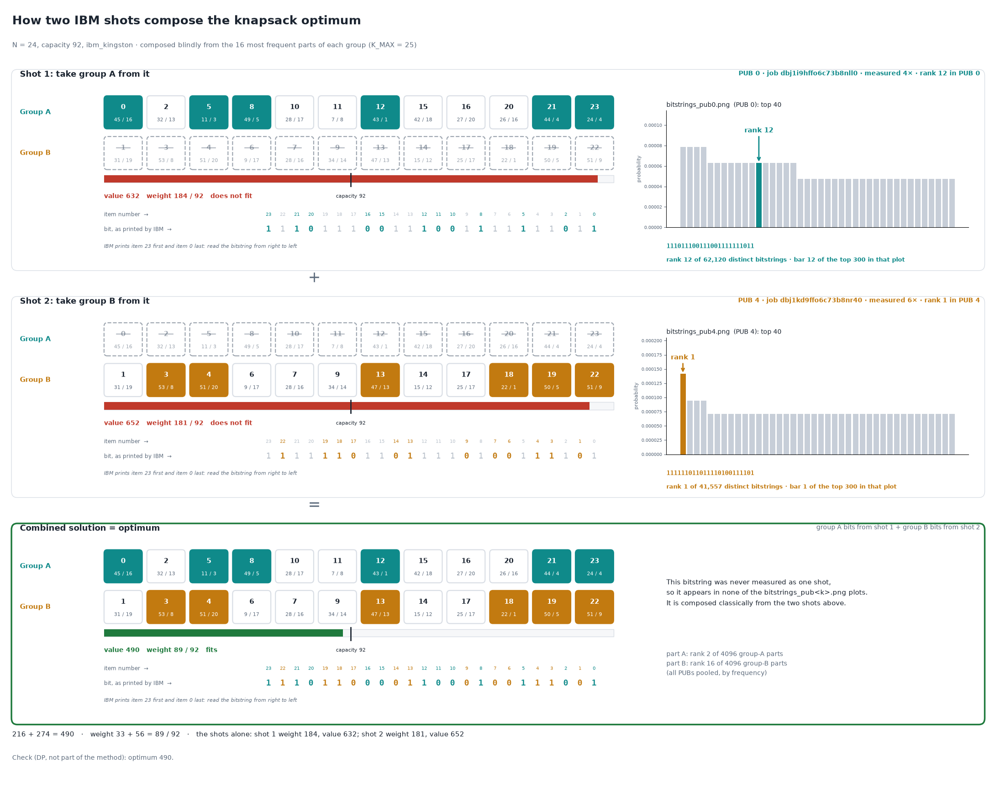

saved: out_N24_groups/composing_the_optimum.png
shot 1: PUB 0  job dbj1i9hffo6c73b8nll0  111011100111001111111011  4x  rank 12 in bitstrings_pub0.png
shot 2: PUB 4  job dbj1kd9ffo6c73b8nr40  111111011011110100111101  6x  rank 1 in bitstrings_pub4.png
combined: 111011000011000100111001  value 490  (never measured as one shot)


In [1]:
# ===========================================================================
#  HOW THE OPTIMUM IS COMPOSED - picture for the notebook
#  Blind: composes the best solution from the K_MAX most frequent parts of each
#  group (no knowledge of the optimum), picks one real IBM shot carrying the A part
#  and one carrying the B part, and shows where each shot sits in the bitstring
#  plot of its PUB (bitstrings_pub<k>.png): shot 1 + shot 2 = combined.
# ===========================================================================
import json
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch, Rectangle

PATH       = "out_N24_groups/counts_N24_ibm_kingston.json"
K_MAX      = 25                     # fix before looking at a new run
PICK       = {"A": None, "B": None} # PUB to take each shot from, e.g. {"A": 0, "B": 1}; None = most frequent shot
TOP_K_PLOT = 300                    # TOP_K used for bitstrings_pub<k>.png in the notebook
TOP_SHOW   = 40                     # bars shown in the excerpt of that plot
OUT        = "out_N24_groups/composing_the_optimum.png"

d = json.load(open(PATH))
V, W, CAP, N = d["values"], d["weights"], d["capacity"], len(d["values"])
GN = list(d["groups"].keys())
GROUPS = list(d["groups"].values())
GMASK = [sum(1 << i for i in g) for g in GROUPS]
COL = {0: "#0f8a8a", 1: "#c27a10"}          # group A teal, group B amber
GREY, INK, MUTED, GOOD, BAD = "#d9dee5", "#1b2430", "#5d6b7c", "#1f7a3d", "#c0392b"

val = lambda m: sum(V[i] for i in range(N) if m >> i & 1)
wt = lambda m: sum(W[i] for i in range(N) if m >> i & 1)
grp = lambda i: 0 if i in GROUPS[0] else 1

# --- blind composition from the most frequent parts ------------------------
freq = [Counter(), Counter()]
for p in d["pubs"]:
    for b, n in p["counts"].items():
        m = int(b, 2)
        for g in range(2):
            freq[g][m & GMASK[g]] += n
ranked = [[m for m, _ in freq[g].most_common()] for g in range(2)]
best = (0, None, None, None)
for K in range(1, K_MAX + 1):
    for ma in ranked[0][:K]:
        for mb in ranked[1][:K]:
            if wt(ma | mb) <= CAP and val(ma | mb) > best[0]:
                best = (val(ma | mb), ma, mb, K)
value, partA, partB, k_first = best
parts = [partA, partB]

# --- ranking of every PUB exactly as bitstrings_pub<k>.png orders its bars ---
def pub_order(p):
    keys = list(p["counts"])
    cnt = np.array([p["counts"][k] for k in keys], float)
    idx = np.argsort(-cnt, kind="stable")
    return [keys[i] for i in idx], cnt[idx] / cnt.sum()

ORDER = {p["pub"]: pub_order(p) for p in d["pubs"]}

# --- one real shot carrying each part ---------------------------------------
def carrier(g, pub):
    cand = Counter()
    for p in d["pubs"]:
        if pub is not None and p["pub"] != pub:
            continue
        for b, n in p["counts"].items():
            if int(b, 2) & GMASK[g] == parts[g]:
                cand[(p["pub"], p["job_id"], b)] += n
    (pb, job, bits), n = cand.most_common(1)[0]
    keys, _ = ORDER[pb]
    return dict(pub=pb, job=job, bits=bits, count=n, mask=int(bits, 2),
                rank=keys.index(bits) + 1, distinct=len(keys))

shot = [carrier(0, PICK["A"]), carrier(1, PICK["B"])]
comb = partA | partB
comb_bits = format(comb, f"0{N}b")
comb_seen = [(p["pub"], p["counts"][comb_bits]) for p in d["pubs"] if comb_bits in p["counts"]]

# --- drawing -----------------------------------------------------------------
TW, TH, GAP = 1.0, 0.78, 0.12
X_TILES = 12 * (TW + GAP) - GAP        # right edge of the tiles
X_RIGHT = 23.0                         # right edge of the panels

def frame(ax, y0, border=None):
    ax.add_patch(FancyBboxPatch((-2.4, y0 - 4.85), X_RIGHT + 2.4, 4.7,
                                boxstyle="round,pad=0.02,rounding_size=0.15",
                                fc="white", ec=border or GREY, lw=2.5 if border else 1))

def tiles_bar_bits(ax, y0, chosen, used, keep):
    for g in range(2):
        yy = y0 - 0.75 - g * (TH + 0.18)
        ax.text(-2.2, yy - TH / 2, f"Group {GN[g]}", fontsize=11, fontweight="bold",
                color=COL[g], va="center")
        for k, i in enumerate(GROUPS[g]):
            x = k * (TW + GAP)
            on, use = (chosen >> i) & 1, (used >> i) & 1
            if on and use:
                fc, ec, ls, tc, a = COL[g], COL[g], "-", "white", 1.0
            elif on:
                fc, ec, ls, tc, a = "white", MUTED, "--", MUTED, 0.6
            else:
                fc, ec, ls, tc, a = "white", GREY, "-", MUTED, 1.0
            ax.add_patch(FancyBboxPatch((x, yy - TH), TW, TH, boxstyle="round,pad=0,rounding_size=0.08",
                                        fc=fc, ec=ec, ls=ls, lw=1.6, alpha=a))
            ax.text(x + TW / 2, yy - 0.27, str(i), ha="center", va="center", fontsize=11,
                    fontweight="bold", color=tc if (on and use) else (MUTED if on else INK), alpha=a)
            ax.text(x + TW / 2, yy - 0.57, f"{V[i]} / {W[i]}", ha="center", va="center",
                    fontsize=8, color=tc, alpha=a)
            if on and not use:
                ax.plot([x + 0.32, x + 0.68], [yy - 0.27, yy - 0.27], color=MUTED, lw=1.2, alpha=a)
    yb, maxw = y0 - 2.8, 190
    w_, v_ = wt(chosen), val(chosen)
    ax.add_patch(Rectangle((0, yb), X_TILES, 0.18, fc="#f6f7f9", ec=GREY))
    ax.add_patch(Rectangle((0, yb), X_TILES * min(1, w_ / maxw), 0.18, fc=GOOD if w_ <= CAP else BAD))
    ax.plot([X_TILES * CAP / maxw] * 2, [yb - 0.08, yb + 0.22], color=INK, lw=2)
    ax.text(X_TILES * CAP / maxw, yb - 0.32, f"capacity {CAP}", fontsize=8, color=INK,
            ha="center", va="center")
    ax.text(0, yb - 0.32, f"value {v_}   weight {w_} / {CAP}   "
            + ("fits" if w_ <= CAP else "does not fit"),
            fontsize=10, color=GOOD if w_ <= CAP else BAD, fontweight="bold", va="center")
    bits = format(chosen, f"0{N}b")
    y_item, y_bit = y0 - 3.55, y0 - 3.9
    ax.text(0, y_item, "item number  →", fontsize=8.5, color=MUTED, va="center")
    ax.text(0, y_bit, "bit, as printed by IBM  →", fontsize=8.5, color=MUTED, va="center")
    ax.text(0, y0 - 4.3, "IBM prints item 23 first and item 0 last: read the bitstring from right to left",
            fontsize=8, color=MUTED, va="center", style="italic")
    for k, c in enumerate(bits):
        item = N - 1 - k
        g = grp(item)
        used_digit = keep == "both" or keep == g
        x = 4.3 + k * 0.37
        ax.text(x, y_item, str(item), fontsize=7.5, ha="center", va="center",
                color=COL[g] if used_digit else "#b8c0ca")
        ax.text(x, y_bit, c, family="monospace", fontsize=13, ha="center", va="center",
                fontweight="bold" if used_digit else "normal",
                color=COL[g] if used_digit else "#b8c0ca")

def plot_excerpt(ax, y0, s, g):
    """Excerpt of bitstrings_pub<k>.png with this shot's bar highlighted."""
    keys, prob = ORDER[s["pub"]]
    r = s["rank"]
    show = list(range(min(TOP_SHOW, len(keys))))
    extra = r - 1 not in show
    if extra:
        show.append(r - 1)
    inset = ax.inset_axes([14.7, y0 - 3.85, 7.9, 2.75], transform=ax.transData)
    xs = list(range(len(show)))
    if extra:
        xs[-1] = len(show) + 1                       # leave a gap before the appended bar
    cols = [COL[g] if i == r - 1 else "#c7ced8" for i in show]
    inset.bar(xs, [prob[i] for i in show], color=cols, width=0.8)
    if extra:
        inset.axvline(len(show) - 0.1, color=MUTED, ls="--", lw=1)
    hx = xs[show.index(r - 1)]
    inset.annotate(f"rank {r}", xy=(hx, prob[r - 1]), xytext=(hx, max(prob[show]) * 1.18),
                   ha="center", fontsize=11, fontweight="bold", color=COL[g],
                   arrowprops=dict(arrowstyle="->", lw=2, color=COL[g]))
    inset.set_ylim(0, max(prob[show]) * 1.45)
    inset.set_xticks([])
    inset.tick_params(axis="y", labelsize=7, colors=MUTED)
    for sp in ("top", "right"):
        inset.spines[sp].set_visible(False)
    inset.set_ylabel("probability", fontsize=8, color=MUTED)
    inset.set_title(f"bitstrings_pub{s['pub']}.png  (PUB {s['pub']}): top {TOP_SHOW}"
                    + (" + this shot" if extra else ""), fontsize=10, color=INK, loc="left")
    where = (f"bar {r} of the top {TOP_K_PLOT} in that plot" if r <= TOP_K_PLOT
             else f"outside the top {TOP_K_PLOT} shown in that plot")
    ax.text(14.7, y0 - 4.3, s["bits"], fontsize=10, color=COL[g], fontweight="bold",
            family="monospace", va="center")
    ax.text(14.7, y0 - 4.62, f"rank {r} of {s['distinct']:,} distinct bitstrings · {where}",
            fontsize=9, color=COL[g], fontweight="bold", va="center")

def shot_panel(ax, y0, s, g, part):
    frame(ax, y0)
    ax.text(-2.2, y0 - 0.15, f"Shot {g + 1}: take group {GN[g]} from it", fontsize=13,
            fontweight="bold", color=INK, va="top")
    ax.text(X_RIGHT - 0.1, y0 - 0.15,
            f"PUB {s['pub']} · job {s['job']} · measured {s['count']}× · rank {s['rank']} in PUB {s['pub']}",
            fontsize=10, color=COL[g], fontweight="bold", va="top", ha="right")
    tiles_bar_bits(ax, y0, s["mask"], part, g)
    plot_excerpt(ax, y0, s, g)

fig, ax = plt.subplots(figsize=(22, 17.5))
ax.set_xlim(-2.6, X_RIGHT + 0.3)
ax.set_ylim(-16.9, 1.6)
ax.axis("off")
ax.text(-2.4, 1.35, "How two IBM shots compose the knapsack optimum", fontsize=19,
        fontweight="bold", color=INK, va="top")
ax.text(-2.4, 0.72, f"N = {N}, capacity {CAP}, {d['backend']} · composed blindly from the {k_first} "
        f"most frequent parts of each group (K_MAX = {K_MAX})", fontsize=11, color=MUTED, va="top")

shot_panel(ax, 0.2, shot[0], 0, partA)
ax.text(5.5, -4.85, "+", fontsize=24, color=MUTED, ha="center", va="center")
shot_panel(ax, -5.15, shot[1], 1, partB)
ax.text(5.5, -10.2, "=", fontsize=24, color=MUTED, ha="center", va="center")

y_res = -10.5
is_opt = value == d["optimum"]
frame(ax, y_res, border=GOOD if is_opt else None)
ax.text(-2.2, y_res - 0.15, "Combined solution" + (" = optimum" if is_opt else
        f" ({100 * value / d['optimum']:.1f} % of the optimum)"), fontsize=13, fontweight="bold",
        color=INK, va="top")
ax.text(X_RIGHT - 0.1, y_res - 0.15, "group A bits from shot 1 + group B bits from shot 2",
        fontsize=10, color=MUTED, va="top", ha="right")
tiles_bar_bits(ax, y_res, comb, comb, "both")
if comb_seen:
    note = ("This bitstring was also measured directly as one shot:\n"
            + ", ".join(f"PUB {k}: {n}×" for k, n in comb_seen) + ".")
else:
    note = ("This bitstring was never measured as one shot,\nso it appears in none of the "
            "bitstrings_pub<k>.png plots.\nIt is composed classically from the two shots above.")
ax.text(14.7, y_res - 1.4, note, fontsize=11, color=INK, va="top", linespacing=1.5)
ax.text(14.7, y_res - 3.1,
        f"part A: rank {ranked[0].index(partA) + 1} of {len(ranked[0])} group-A parts\n"
        f"part B: rank {ranked[1].index(partB) + 1} of {len(ranked[1])} group-B parts\n"
        f"(all PUBs pooled, by frequency)", fontsize=10, color=MUTED, va="top", linespacing=1.5)

ax.text(-2.4, -15.65,
        f"{val(partA)} + {val(partB)} = {value}   ·   weight {wt(partA)} + {wt(partB)} = {wt(comb)} / {CAP}   ·   "
        f"the shots alone: shot 1 weight {wt(shot[0]['mask'])}, value {val(shot[0]['mask'])}; "
        f"shot 2 weight {wt(shot[1]['mask'])}, value {val(shot[1]['mask'])}", fontsize=11, color=INK)
ax.text(-2.4, -16.2, f"Check (DP, not part of the method): optimum {d['optimum']}.", fontsize=10,
        color=MUTED)
plt.tight_layout()
os.makedirs(os.path.dirname(OUT), exist_ok=True)
fig.savefig(OUT, dpi=120, bbox_inches="tight")
plt.show()
print(f"saved: {OUT}")
for k, s in enumerate(shot, 1):
    print(f"shot {k}: PUB {s['pub']}  job {s['job']}  {s['bits']}  {s['count']}x  "
          f"rank {s['rank']} in bitstrings_pub{s['pub']}.png")
print(f"combined: {comb_bits}  value {value}"
      + ("" if comb_seen else "  (never measured as one shot)"))
